# Проект Спринта 4: Разведочный анализ данных (EDA)
Домен: SaaS

Выполнила: Наталья Мартынова

## Бизнес-контекст кейса

B2B-сервис для совместной работы и управления проектами FlowBoard исследует динамику использования рабочих пространств за четыре месяца (октябрь 2026 — январь 2027).

В продуктовую линейку входит три коммерческих пакета подписки, закодированных в поле package_code:
- PKG-001 — тариф Starter (в поле product_name: Free Starter Workspace, бесплатный базовый пакет, три рабочих места);
- PKG-002 — тариф Professional (в поле product_name: Professional Monthly Plan, 990 руб./мес, десять рабочих мест);
- PKG-003 — тариф Enterprise (в поле product_name: Professional Annual Plan / Enterprise, 2990 руб./мес, 50 рабочих мест);
- у части строк код пакета не заполнен по итогам очистки в третьем спринте (эти пропуски мы не заполняем).

Аккаунты разделены на пробные и оплачиваемые (поле segment: trial или paid).

Команде роста (Growth) важно оценить, какие пакеты обеспечивают основную долю регулярной месячной выручки (MRR), как активность пользователей связана с тарифным планом и как меняется поведение команд в конце календарного года.

## Ориентировочные бизнес-вопросы для исследования:

1. Какие тарифные пакеты сервиса формируют ключевую долю регулярной выручки (MRR).

2. Как активность пользователей соотносится с тарифом?

3. Наблюдается ли сезонность в поведении корпоративных клиентов?

## Данные кейса

Объём данных: 5000 аккаунтов рабочих пространств за четыре месяца = ровно 20 000 очищенных строк.

Уровень детализации (зернистость): одна строка — активность одного рабочего пространства за один месяц (account_id × snapshot_month).

In [ ]:
# Импорт необходимых библиотек
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
# Загрузим датасет (финальный файл Проекта Спринта 3)
df = pd.read_csv('df.csv')
df.info()
df.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 16 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   account_id           20000 non-null  object 
 1   plan_code            15400 non-null  object 
 2   snapshot_month_norm  20000 non-null  object 
 3   segment              20000 non-null  object 
 4   active_users         19573 non-null  float64
 5   mrr_proxy_rub_num    18364 non-null  float64
 6   status_flag          20000 non-null  object 
 7   product_name         15400 non-null  object 
 8   product_line         15400 non-null  object 
 9   package_code         15400 non-null  object 
 10  price_rub            15400 non-null  float64
 11  seats_included       15092 non-null  float64
 12  comment_text_clean   18947 non-null  object 
 13  comment_theme        18947 non-null  object 
 14  comment_sentiment    18947 non-null  object 
 15  comment_summary      18947 non-null 

,account_id,plan_code,snapshot_month_norm,segment,active_users,mrr_proxy_rub_num,status_flag,product_name,product_line,package_code,price_rub,seats_included,comment_text_clean,comment_theme,comment_sentiment,comment_summary
0,ACC-10001,PLAN-001,2026-10,trial,3.0,NaN,active,free starter workspace,free,PKG-001,0.0,3.0,NaN,NaN,NaN,NaN
1,ACC-10001,PLAN-001,2026-11,trial,14.0,1434.45,active,free starter workspace,free,PKG-001,0.0,3.0,Загрузка ускорилась после последнего обновления.,Обновление / Загрузка,позитивная,ускорение загрузки
2,ACC-10001,PLAN-001,2026-12,trial,15.0,7396.30,active,free starter workspace,free,PKG-001,0.0,3.0,"На пробном периоде не хватило функций, вернули...",Пробный период,негативная,не хватило функций на триале
3,ACC-10001,PLAN-001,2027-01,trial,15.0,7285.36,active,free starter workspace,free,PKG-001,0.0,3.0,"Пробный период понравился, перешли на платный ...",Пробный период / Оплата,позитивная,"понравился триал, переход на платный пакет"
4,ACC-10002,PLAN-003,2026-10,paid,23.0,3521.03,active,professional monthly plan,paid,PKG-002,990.0,10.0,Загрузка ускорилась после последнего обновления.,Обновление / Загрузка,позитивная,ускорение загрузки


**Состав полей (по описанию из задания к проекту):**

- account_id — обезличенный идентификатор рабочего пространства (аккаунта);
- snapshot_month — месяц среза данных в формате ГГГГ-ММ (2026-10, 2026-11, 2026-12, 2027-01);
- plan_code — базовый системный код тарифного плана (PLAN-001–PLAN-004, у части строк пустой по итогам очистки, не заполняется);
- product_name — коммерческое название пакета;
- product_line — линейка продукта;
- package_code — код пакета подписки (PKG-001 — Starter, PKG-002 — Professional, PKG-003 — Enterprise; пустые ячейки не заполняются);
- segment — статус подписки (trial или paid);
- active_users — число активных пользователей в пространстве за месяц;
- mrr_proxy_rub — расчётная месячная регулярная выручка от аккаунта в рублях;
- status_flag — статус аккаунта (active или churned);
- price_rub — базовая стоимость пакета в месяц (0 руб., 990 руб., 2 990 руб.);
- seats_included — число рабочих мест, включённых в пакет (3, 10, 50);
- comment_text — короткий ответ администратора пространства на опрос;
- comment_theme — тема отзыва, размеченная в третьем спринте;
- comment_sentiment — тональность отзыва (позитивная, негативная, нейтральная);
- comment_summary — краткое содержание отзыва.

## Шаг 1. Формулируем бизнес-вопрос и рабочие гипотезы

Сформулируйте:

1. Главный бизнес-вопрос: что именно нужно выяснить для руководства компании? Вы можете опираться на ориентировочный бизнес-вопрос из описания кейса выше или сформулировать свой вариант под выбранный ракурс исследования.

2. Две-три рабочие гипотезы: какие взаимосвязи или распределения мы ожидаем увидеть в данных?

В Спринте 1 мы создали скилл по уточнению бизнес- и аналитической задачи из неструктурированного запроса. Я воспользовалась своим на этом шаге. Прикрепила к запросу скилл, контекст и исходные данные, описанные выше.

В итоге был получен следующий

ОТВЕТ:

Теперь есть всё, чтобы перейти от постановки к гипотезам: зерно данных (`account_id` × `snapshot_month`) зафиксировано, пустые `package_code` не заполняем, период Q4 2026 + январь 2027 принят как корректный для проекта.

## 1. Главный бизнес-вопрос

**Какие пакеты подписки формируют основную долю MRR (по `mrr_proxy_rub`), как активность аккаунтов (`active_users`) связана с пакетом и как меняются выручка, активность и отток аккаунтов от октября 2026 к январю 2027?**

Для Growth это показывает, на какие пакеты и какой уровень активности направлять усилия (удержание, апгрейды, работа с триалами). Для руководства это показывает, насколько выручка зависит от одного-двух пакетов и есть ли предновогодний риск.

Единица анализа: аккаунт-месяц. Выручку и активность сравниваем между пакетами и месяцами. Пустой `package_code` (23% строк) идёт отдельной категорией «не определён».

## 2. Рабочие гипотезы

**H1. Выручка сконцентрирована в платных пакетах.**
Доля аккаунтов и доля MRR по пакетам не совпадают. Starter даёт большую часть аккаунтов, но малую долю MRR, а Professional и Enterprise вместе дают основную часть MRR при меньшей доле аккаунтов.
- *Проверка:* `groupby('package_code')`, сравнение долей аккаунтов и MRR; столбчатая диаграмма долей и boxplot/violin `mrr_proxy_rub` по пакетам.
- *Опровержение:* доли MRR примерно равны долям аккаунтов или основная выручка приходится на Starter.

**H2. Активность растёт вместе с размером пакета, но не пропорционально числу мест.**
Медиана `active_users` растёт от Starter к Enterprise, а загрузка мест (`active_users / seats_included`) различается по пакетам. Активность положительно коррелирует с `mrr_proxy_rub`.
- *Проверка:* распределения `active_users` по пакетам (гистограммы, ECDF), матрица корреляций (Spearman) для `active_users`, `mrr_proxy_rub`, `price_rub`, `seats_included`, непараметрический тест различий между пакетами.
- *Опровержение:* распределения активности по пакетам не различаются или связь с MRR слабая.

**H3. К концу года поведение меняется: активность и MRR в декабре–январе отличаются от октября–ноября, а отток и негативная тональность связаны с низкой активностью.**
Ожидаем сдвиг по месяцам (сильнее у trial, чем у paid). Аккаунты со `status_flag = churned` имеют более низкую активность и чаще негативные комментарии (`comment_sentiment`).
- *Проверка:* линейные графики медианы `active_users` и суммарного MRR по месяцам в разрезе `segment` и пакета; доля churned по месяцам; сравнение активности churned и active; доля тональностей по группам.
- *Опровержение:* динамика по месяцам плоская или одинакова во всех группах, а churned не отличаются от active по активности.

## Что проверить до проверки гипотез

По первой строке фрагмента видны вещи, которые влияют на интерпретацию:
- **`mrr_proxy_rub` не равен `price_rub`.** У ACC-10001 цена 0 руб., а MRR 1 434 – 7 396 руб. Нужно выяснить, как считается proxy, иначе H1 легко прочитать неверно.
- **`active_users` выше `seats_included`.** У аккаунта 14–15 активных пользователей при 3 включённых местах. Нужно понять, это норма (гостевые доступы) или шум.
- **Комментарии и статус не всегда согласованы.** В январе при `segment = trial` и PKG-001 стоит комментарий о переходе на платный пакет. Такие случаи надо учитывать при работе с тональностью.
- **Пропуски.** Поля пакета (`plan_code`, `product_name`, `product_line`, `package_code`, `price_rub`) пустые в одних и тех же 4 600 строках, `seats_included` ещё чаще. Проверьте, равномерно ли пропуски распределены по месяцам, `segment` и `status_flag`: от этого зависит, насколько доли по пакетам репрезентативны.
- **Баланс панели.** Убедитесь, что у каждого аккаунта есть строки за все четыре месяца: из 20 000 строк это 5 000 аккаунтов, только если панель сбалансирована.

Если подтвердите формулировки, на следующем шаге перейду к плану EDA: структура выборки, распределения, корреляции и код проверки каждой гипотезы.

КОНЕЦ ОТВЕТА МОДЕЛИ


## Шаг 2. Описываем данные

Зафиксируйте паспорт набора данных:

- источник и объём выборки (5000 объектов, четыре месяца, 20 000 строк);
- уровень детализации таблицы (зернистость: что представляет собой одна строка данных);
- состав ключевых числовых и категориальных полей с типами данных pandas (float64, int64, object);
- отметка о чистоте данных: подтверждение, что данные проверены, дубликаты устранены, а невалидные значения приведены к NaN без синтетических средних.

ПАСПОРТ НАБОРА ДАННЫХ:

Мы работаем с данными B2B-сервиса для совместной работы и управления проектами FlowBoard, исследуем динамику использования рабочих пространств за четыре месяца (октябрь 2026 — январь 2027).

В датасете df 5000 аккаунтов рабочих пространств за четыре месяца = ровно 20 000 очищенных строк.

Уровень детализации (зернистость): одна строка — активность одного рабочего пространства за один месяц (account_id × snapshot_month).

Состав полей:
```
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   account_id           20000 non-null  object
 1   plan_code            15400 non-null  object
 2   snapshot_month_norm  20000 non-null  object
 3   segment              20000 non-null  object
 4   active_users         19573 non-null  float64
 5   mrr_proxy_rub_num    18364 non-null  float64
 6   status_flag          20000 non-null  object
 7   product_name         15400 non-null  object
 8   product_line         15400 non-null  object
 9   package_code         15400 non-null  object
 10  price_rub            15400 non-null  float64
 11  seats_included       15092 non-null  float64
 12  comment_text_clean   18947 non-null  object
 13  comment_theme        18947 non-null  object
 14  comment_sentiment    18947 non-null  object
 15  comment_summary      18947 non-null  object
dtypes: float64(4), object(12)
```
Данные проверены, дубликаты устранены, а невалидные значения приведены к NaN без синтетических средних.

При постановке задач на генерацию кода Python просто укажите модели расшифровку кодов в контексте запроса: Добавь в DataFrame текстовую колонку категории и сделай группировку выручки. Модель автоматически сгенерирует аккуратный маппинг в коде для расчётов и подписей графиков.

ЗАПРОС:
```
Мы работаем с датасетом df: cостав полей:
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   account_id           20000 non-null  object
 1   plan_code            15400 non-null  object
 2   snapshot_month_norm  20000 non-null  object
 3   segment              20000 non-null  object
 4   active_users         19573 non-null  float64
 5   mrr_proxy_rub_num    18364 non-null  float64
 6   status_flag          20000 non-null  object
 7   product_name         15400 non-null  object
 8   product_line         15400 non-null  object
 9   package_code         15400 non-null  object
 10  price_rub            15400 non-null  float64
 11  seats_included       15092 non-null  float64
 12  comment_text_clean   18947 non-null  object
 13  comment_theme        18947 non-null  object
 14  comment_sentiment    18947 non-null  object
 15  comment_summary      18947 non-null  object
dtypes: float64(4), object(12)
Напиши код для Python pandas в Colab: lобавь в DataFrame df текстовую колонку категории:
PKG-001 — тариф Starter;
PKG-002 — тариф Professional;
PKG-003 — тариф Enterprise.
И добавь группировку выручки.
```

ОТВЕТ:

```
import pandas as pd

# ==============================================================================
# 1. Добавление текстовой колонки категории пакета
# ==============================================================================
# Словарь соответствий кодов пакетов их названиям
package_mapping = {
    'PKG-001': 'Starter',
    'PKG-002': 'Professional',
    'PKG-003': 'Enterprise'
}

# Создаём новую колонку package_category через map
# Значения вне словаря автоматически станут NaN
df['package_category'] = df['package_code'].map(package_mapping)

# Проверка результата
print("=== Распределение новых категорий ===")
print(df['package_category'].value_counts(dropna=False))

# ==============================================================================
# 2. Группировка выручки (mrr_proxy_rub_num) по категории пакета
# ==============================================================================
# Агрегация: сумма MRR, количество аккаунтов и доля в общей выручке
revenue_by_package = (
    df.groupby('package_category', dropna=False)['mrr_proxy_rub_num']
    .agg(['sum', 'count'])
    .rename(columns={'sum': 'mrr_total_rub', 'count': 'account_count'})
    .reset_index()
)

# Расчёт доли каждого пакета в общей выручке (%)
total_mrr = revenue_by_package['mrr_total_rub'].sum()
revenue_by_package['mrr_share_pct'] = (
    revenue_by_package['mrr_total_rub'] / total_mrr * 100
)

print("\n=== Группировка выручки по категории пакета ===")
print(revenue_by_package)

# ==============================================================================
# 3. Динамика выручки по месяцам в разрезе категорий пакета
# ==============================================================================
revenue_by_month_package = (
    df.groupby(['snapshot_month_norm', 'package_category'], dropna=False)['mrr_proxy_rub_num']
    .sum()
    .reset_index()
    .rename(columns={'mrr_proxy_rub_num': 'mrr_total_rub'})
)

print("\n=== Динамика выручки по месяцам и категории пакета ===")
print(revenue_by_month_package)
```

**Что делает код:**

1. **Создание колонки `package_category`** — через `map()` по полю `package_code`. Значения, которых нет в словаре (включая NaN из 4600 пустых `package_code`), останутся `NaN` — это важно, так как не все строки имеют заполненный тариф.

2. **Группировка выручки по пакету** — считает суммарный MRR, число аккаунтов и долю каждого пакета в общей выручке. Это позволяет напрямую проверить H1 (концентрация выручки в платных пакетах).

3. **Динамика выручки по месяцам** — показывает, как менялся MRR по категориям от октября 2026 к январю 2027, что соответствует H3.

**Что проверить после выполнения:**
- Все ли три категории (`Starter`, `Professional`, `Enterprise`) появились и сколько строк осталось с `NaN`.
- Сумма `mrr_share_pct` должна давать 100%.
- Порядок месяцев в динамике: `2026-10`, `2026-11`, `2026-12`, `2027-01` — убедиться, что нет пропусков.

КОНЕЦ ОТВЕТА МОДЕЛИ

In [16]:
# ==============================================================================
# 1. Добавление текстовой колонки категории пакета
# ==============================================================================
# Словарь соответствий кодов пакетов их названиям
package_mapping = {
    'PKG-001': 'Starter',
    'PKG-002': 'Professional',
    'PKG-003': 'Enterprise'
}

# Создаём новую колонку package_category через map
# Значения вне словаря автоматически станут NaN
df['package_category'] = df['package_code'].map(package_mapping)

# Проверка результата
print("=== Распределение новых категорий ===")
print(df['package_category'].value_counts(dropna=False))

# ==============================================================================
# 2. Группировка выручки (mrr_proxy_rub_num) по категории пакета
# ==============================================================================
# Агрегация: сумма MRR, количество аккаунтов и доля в общей выручке
revenue_by_package = (
    df.groupby('package_category', dropna=False)['mrr_proxy_rub_num']
    .agg(['sum', 'count'])
    .rename(columns={'sum': 'mrr_total_rub', 'count': 'account_count'})
    .reset_index()
)

# Расчёт доли каждого пакета в общей выручке (%)
total_mrr = revenue_by_package['mrr_total_rub'].sum()
revenue_by_package['mrr_share_pct'] = (
    revenue_by_package['mrr_total_rub'] / total_mrr * 100
)

print("\n=== Группировка выручки по категории пакета ===")
display(revenue_by_package)

# ==============================================================================
# 3. Динамика выручки по месяцам в разрезе категорий пакета
# ==============================================================================
revenue_by_month_package = (
    df.groupby(['snapshot_month_norm', 'package_category'], dropna=False)['mrr_proxy_rub_num']
    .sum()
    .reset_index()
    .rename(columns={'mrr_proxy_rub_num': 'mrr_total_rub'})
)

print("\n=== Динамика выручки по месяцам и категории пакета ===")
display(revenue_by_month_package)

=== Распределение новых категорий ===
package_category
Starter         7100
NaN             4600
Enterprise      4200
Professional    4100
Name: count, dtype: int64

=== Группировка выручки по категории пакета ===


,package_category,mrr_total_rub,account_count,mrr_share_pct
0,Enterprise,8.749753e+07,3857,20.338332
1,Professional,8.978135e+07,3773,20.869193
2,Starter,1.465062e+08,6527,34.054578
3,NaN,1.064249e+08,4207,24.737897



=== Динамика выручки по месяцам и категории пакета ===


,snapshot_month_norm,package_category,mrr_total_rub
0,2026-10,Enterprise,21024969.60
1,2026-10,Professional,23139958.66
2,2026-10,Starter,38432178.92
3,2026-10,NaN,26949746.84
4,2026-11,Enterprise,18062470.54
5,2026-11,Professional,19398776.61
6,2026-11,Starter,35866551.45
7,2026-11,NaN,29058500.00
8,2026-12,Enterprise,24144786.44
9,2026-12,Professional,23528142.05


Проверки после выполнения кода:

1. Все три категории (Starter, Professional, Enterprise) появились. С NaN осталось 4600 строк (20000 - 15400 так и должно быть).

2. Сумма mrr_share_pct даёт 100%.

3. Порядок месяцев в динамике: 2026-10, 2026-11, 2026-12, 2027-01 - всё верно. Все месяца присутствуют.

## Шаг 3. Запрашиваем первичные описательные статистики и корреляции через Python

Попросите языковую модель сгенерировать компактный и чистый код на pandas для Google Colab.

ЗАПРОС:
```
Мы работаем с данными B2B-сервиса для совместной работы и управления проектами FlowBoard, исследуем динамику использования рабочих пространств за четыре месяца (октябрь 2026 — январь 2027). В датасете df 5000 аккаунтов рабочих пространств за четыре месяца = ровно 20 000 очищенных строк. Уровень детализации (зернистость): одна строка — активность одного рабочего пространства за один месяц (account_id × snapshot_month). Данные проверены, дубликаты устранены, а невалидные значения приведены к NaN без синтетических средних.
Задача - сгенерировать понятный и воспроизводимый Python-скрипт на pandas, который выводит базовую информацию (.info(), размерность .shape), рассчитывает ключевые статистики (среднее, медиану, квартили Q1 и Q3, межквартильный размах IQR, минимум и максимум), определяет границу выбросов по правилу Q3 + 1,5 × IQR, вычисляет корреляционную матрицу числовых признаков (.corr()) и группирует данные по ключевым сегментам.
Ограничения: стандартный стек (pandas, numpy), аккуратные короткие комментарии к кодовым блокам. Не изменяй данные и не сохраняй файлы. Другие расчёты не добавляй. Конкретные функции выбери сам — главное, чтобы по ответу можно было проверить цифры.
```

ОТВЕТ:
```
import pandas as pd
import numpy as np

# Базовая информация о датасете
print("=== БАЗОВАЯ ИНФОРМАЦИЯ ===")
print(f"Размерность: {df.shape}")
print(f"\nИнформация о столбцах:")
df.info()

# Числовые колонки для анализа
numeric_cols = ['active_users', 'mrr_proxy_rub_num', 'price_rub', 'seats_included']

# Ключевые статистики
print("\n=== КЛЮЧЕВЫЕ СТАТИСТИКИ ===")
for col in numeric_cols:
    if col in df.columns:
        q1 = df[col].quantile(0.25)
        q3 = df[col].quantile(0.75)
        iqr = q3 - q1
        
        print(f"\n{col}:")
        print(f"  Среднее: {df[col].mean():.2f}")
        print(f"  Медиана: {df[col].median():.2f}")
        print(f"  Q1: {q1:.2f}")
        print(f"  Q3: {q3:.2f}")
        print(f"  IQR: {iqr:.2f}")
        print(f"  Минимум: {df[col].min():.2f}")
        print(f"  Максимум: {df[col].max():.2f}")

# Границы выбросов по правилу Q3 + 1.5 × IQR
print("\n=== ГРАНИЦЫ ВЫБРОСОВ (Q3 + 1.5 × IQR) ===")
for col in numeric_cols:
    if col in df.columns:
        q3 = df[col].quantile(0.75)
        iqr = df[col].quantile(0.75) - df[col].quantile(0.25)
        upper_bound = q3 + 1.5 * iqr
        
        print(f"{col}: верхняя граница = {upper_bound:.2f}")

# Корреляционная матрица числовых признаков
print("\n=== КОРРЕЛЯЦИОННАЯ МАТРИЦА ===")
corr_matrix = df[numeric_cols].corr()
print(corr_matrix.round(3))

# Группировка по ключевым сегментам
print("\n=== ГРУППИРОВКА ПО СЕГМЕНТАМ ===")

# Группировка по segment
print("\nСредние значения по segment:")
segment_stats = df.groupby('segment')[numeric_cols].agg(['mean', 'median', 'count'])
print(segment_stats.round(2))

# Группировка по plan_code
print("\nСредние значения по plan_code:")
plan_stats = df.groupby('plan_code')[numeric_cols].agg(['mean', 'median', 'count'])
print(plan_stats.round(2))

# Группировка по product_line
print("\nСредние значения по product_line:")
product_stats = df.groupby('product_line')[numeric_cols].agg(['mean', 'median', 'count'])
print(product_stats.round(2))

# Группировка по package_code
print("\nСредние значения по package_code:")
package_stats = df.groupby('package_code')[numeric_cols].agg(['mean', 'median', 'count'])
print(package_stats.round(2))
```

КОНЕЦ ОТВЕТА МОДЕЛИ

In [13]:
# Базовая информация о датасете
print("=== БАЗОВАЯ ИНФОРМАЦИЯ ===")
print(f"Размерность: {df.shape}")
print(f"\nИнформация о столбцах:")
df.info()

# Числовые колонки для анализа
numeric_cols = ['active_users', 'mrr_proxy_rub_num', 'price_rub', 'seats_included']

# Ключевые статистики
print("\n=== КЛЮЧЕВЫЕ СТАТИСТИКИ ===")
for col in numeric_cols:
    if col in df.columns:
        q1 = df[col].quantile(0.25)
        q3 = df[col].quantile(0.75)
        iqr = q3 - q1

        print(f"\n{col}:")
        print(f"  Среднее: {df[col].mean():.2f}")
        print(f"  Медиана: {df[col].median():.2f}")
        print(f"  Q1: {q1:.2f}")
        print(f"  Q3: {q3:.2f}")
        print(f"  IQR: {iqr:.2f}")
        print(f"  Минимум: {df[col].min():.2f}")
        print(f"  Максимум: {df[col].max():.2f}")

# Границы выбросов по правилу Q3 + 1.5 × IQR
print("\n=== ГРАНИЦЫ ВЫБРОСОВ (Q3 + 1.5 × IQR) ===")
for col in numeric_cols:
    if col in df.columns:
        q3 = df[col].quantile(0.75)
        iqr = df[col].quantile(0.75) - df[col].quantile(0.25)
        upper_bound = q3 + 1.5 * iqr

        print(f"{col}: верхняя граница = {upper_bound:.2f}")

# Корреляционная матрица числовых признаков
print("\n=== КОРРЕЛЯЦИОННАЯ МАТРИЦА ===")
corr_matrix = df[numeric_cols].corr()
display(corr_matrix.round(3))

# Группировка по ключевым сегментам
print("\n=== ГРУППИРОВКА ПО СЕГМЕНТАМ ===")

# Группировка по segment
print("\nСредние значения по segment:")
segment_stats = df.groupby('segment')[numeric_cols].agg(['mean', 'median', 'count'])
display(segment_stats.round(2))

# Группировка по plan_code
print("\nСредние значения по plan_code:")
plan_stats = df.groupby('plan_code')[numeric_cols].agg(['mean', 'median', 'count'])
display(plan_stats.round(2))

# Группировка по product_line
print("\nСредние значения по product_line:")
product_stats = df.groupby('product_line')[numeric_cols].agg(['mean', 'median', 'count'])
display(product_stats.round(2))

# Группировка по package_code
print("\nСредние значения по package_code:")
package_stats = df.groupby('package_code')[numeric_cols].agg(['mean', 'median', 'count'])
display(package_stats.round(2))

=== БАЗОВАЯ ИНФОРМАЦИЯ ===
Размерность: (20000, 17)

Информация о столбцах:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 17 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   account_id           20000 non-null  object 
 1   plan_code            15400 non-null  object 
 2   snapshot_month_norm  20000 non-null  object 
 3   segment              20000 non-null  object 
 4   active_users         19573 non-null  float64
 5   mrr_proxy_rub_num    18364 non-null  float64
 6   status_flag          20000 non-null  object 
 7   product_name         15400 non-null  object 
 8   product_line         15400 non-null  object 
 9   package_code         15400 non-null  object 
 10  price_rub            15400 non-null  float64
 11  seats_included       15092 non-null  float64
 12  comment_text_clean   18947 non-null  object 
 13  comment_theme        18947 non-null  object 
 14  comment_se

,active_users,mrr_proxy_rub_num,price_rub,seats_included
active_users,1.000,0.083,-0.001,0.005
mrr_proxy_rub_num,0.083,1.000,0.005,-0.000
price_rub,-0.001,0.005,1.000,0.982
seats_included,0.005,-0.000,0.982,1.000



=== ГРУППИРОВКА ПО СЕГМЕНТАМ ===

Средние значения по segment:


active_users               mrr_proxy_rub_num                   \
                mean median  count              mean    median  count   
segment                                                                 
paid           11.65   11.0   8123          23234.45  22780.31   7630   
trial          11.78   11.0  11450          23563.54  23851.21  10734   

        price_rub               seats_included               
             mean  median count           mean median count  
segment                                                      
paid      2002.05  2990.0  8300          30.24   50.0  8120  
trial        0.00     0.0  7100           3.00    3.0  6972


Средние значения по plan_code:


active_users              mrr_proxy_rub_num                  \
                  mean median count              mean    median count   
plan_code                                                               
PLAN-001         11.51   11.0  3617          22763.68  22463.53  3393   
PLAN-002         12.51   13.0  3325          22102.44  18887.49  3134   
PLAN-003         11.36   10.0  4007          23795.74  23960.12  3773   
PLAN-004         11.94   12.0  4116          22685.39  21182.67  3857   

          price_rub               seats_included               
               mean  median count           mean median count  
plan_code                                                      
PLAN-001        0.0     0.0  3700            3.0    3.0  3626  
PLAN-002        0.0     0.0  3400            3.0    3.0  3346  
PLAN-003      990.0   990.0  4100           10.0   10.0  4011  
PLAN-004     2990.0  2990.0  4200           50.0   50.0  4109


Средние значения по product_line:


active_users              mrr_proxy_rub_num                  \
                     mean median count              mean    median count   
product_line                                                               
free                11.99   12.0  6942          22446.18  21809.25  6527   
paid                11.65   11.0  8123          23234.45  22780.31  7630   

             price_rub               seats_included               
                  mean  median count           mean median count  
product_line                                                      
free              0.00     0.0  7100           3.00    3.0  6972  
paid           2002.05  2990.0  8300          30.24   50.0  8120


Средние значения по package_code:


active_users              mrr_proxy_rub_num                  \
                     mean median count              mean    median count   
package_code                                                               
PKG-001             11.99   12.0  6942          22446.18  21809.25  6527   
PKG-002             11.36   10.0  4007          23795.74  23960.12  3773   
PKG-003             11.94   12.0  4116          22685.39  21182.67  3857   

             price_rub               seats_included               
                  mean  median count           mean median count  
package_code                                                      
PKG-001            0.0     0.0  7100            3.0    3.0  6972  
PKG-002          990.0   990.0  4100           10.0   10.0  4011  
PKG-003         2990.0  2990.0  4200           50.0   50.0  4109

## Шаг 4. Выбираем и строим графики через код

Каждая визуализация должна подтверждать или опровергать конкретную гипотезу. Обсудите выбор библиотек и типов диаграмм с ИИ.

ЗАПРОС:
```
Ты - аналитик данных. В данном проекте перед тобой стоит бизнес-вопрос: какие пакеты подписки формируют основную долю MRR (по mrr_proxy_rub_num), как активность аккаунтов (active_users) связана с пакетом (package_code) и как меняются выручка, активность и отток аккаунтов от октября 2026 к январю 2027. Рабочие гипотезы:
H1. Выручка сконцентрирована в платных пакетах. Доля аккаунтов и доля MRR по пакетам не совпадают. Starter даёт большую часть аккаунтов, но малую долю MRR, а Professional и Enterprise вместе дают основную часть MRR при меньшей доле аккаунтов.
H2. Активность растёт вместе с размером пакета, но не пропорционально числу мест. Медиана active_users растёт от Starter к Enterprise, а загрузка мест (active_users / seats_included) различается по пакетам. Активность положительно коррелирует с mrr_proxy_rub.
H3. К концу года поведение меняется: активность и MRR в декабре–январе отличаются от октября–ноября, а отток и негативная тональность связаны с низкой активностью. Ожидаем сдвиг по месяцам (сильнее у trial, чем у paid). Аккаунты со status_flag = churned имеют более низкую активность и чаще негативные комментарии (comment_sentiment).
Структура полей датасета df:
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   account_id           20000 non-null  object
 1   plan_code            15400 non-null  object
 2   snapshot_month_norm  20000 non-null  object
 3   segment              20000 non-null  object
 4   active_users         19573 non-null  float64
 5   mrr_proxy_rub_num    18364 non-null  float64
 6   status_flag          20000 non-null  object
 7   product_name         15400 non-null  object
 8   product_line         15400 non-null  object
 9   package_code         15400 non-null  object
 10  price_rub            15400 non-null  float64
 11  seats_included       15092 non-null  float64
 12  comment_text_clean   18947 non-null  object
 13  comment_theme        18947 non-null  object
 14  comment_sentiment    18947 non-null  object
 15  comment_summary      18947 non-null  object
 16  package_category     15400 non-null  object
dtypes: float64(4), object(13)
Среда выполнения: Google Colab. Библиотеки: matplotlib, seaborn или plotly.
Задача - порекомендовать два-три конкретных типа визуализаций под гипотезы и написать чистый Python-код для их построения.
Требования к оформлению: понятные названия диаграмм, подписанные оси с единицами измерения (руб., шт., %), читаемая легенда, единая тема оформления (sns.set_theme(style='whitegrid') или аналогичная) и удобный размер фигур (figsize=(10, 5)).
Используй только данные датасета df. Не придумывай значения и не объясняй причины наблюдаемой связи. Напиши что проверить после построения.
```

ОТВЕТ:

Для проверки ваших бизнес-гипотез рекомендую следующие три типа визуализаций. Они напрямую отвечают на поставленные вопросы, используют новую колонку `package_category` и строго соответствуют требованиям к оформлению.

### Рекомендуемые типы визуализаций:
1. **Сгруппированная столбчатая диаграмма (Grouped Bar Chart)** – для проверки **H1**. Наглядно сопоставляет долю аккаунтов и долю MRR по каждой категории пакета на одном графике.
2. **Ящик с усами (Boxplot)** – для проверки **H2**. Показывает медиану, квартили и выбросы активности (`active_users`) в разрезе категорий пакетов, подтверждая рост центрального значения. (Дополнительно: столбчатая диаграмма медианной загрузки мест).
3. **Линейный график с маркерами (Line Plot)** – для проверки **H3**. Демонстрирует динамику медианной активности по месяцам в разрезе статуса аккаунта, позволяя отследить сдвиги в конце года и разрыв между ушедшими и текущими клиентами.

---

### Python-код для построения визуализаций

```
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Единая тема оформления
sns.set_theme(style='whitegrid')

# Определяем логический порядок категорий для осей X
pkg_order = ['Starter', 'Professional', 'Enterprise']

# ==============================================================================
# Визуализация 1: Проверка H1 (Доля аккаунтов vs Доля MRR по категориям пакетов)
# ==============================================================================
# Расчет долей без изменения исходного датафрейма
acc_share = (df['package_category'].value_counts(normalize=True) * 100).rename('Доля аккаунтов (%)')
mrr_share = ((df.groupby('package_category')['mrr_proxy_rub_num'].sum() / df['mrr_proxy_rub_num'].sum()) * 100).rename('Доля MRR (%)')

h1_df = pd.concat([acc_share, mrr_share], axis=1).reset_index()
h1_df_melted = h1_df.melt(id_vars='package_category', var_name='Метрика', value_name='Значение (%)')

plt.figure(figsize=(10, 5))
sns.barplot(
    data=h1_df_melted,
    x='package_category',
    y='Значение (%)',
    hue='Метрика',
    palette='Set2',
    order=pkg_order
)
plt.title('H1: Сравнение доли аккаунтов и доли MRR по категориям пакетов')
plt.xlabel('Категория пакета (package_category)')
plt.ylabel('Доля (%)')
plt.legend(title='Метрика')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# ==============================================================================
# Визуализация 2: Проверка H2 (Распределение активности и загрузка мест)
# ==============================================================================
# 2a. Ящик с усами для активности
plt.figure(figsize=(10, 5))
sns.boxplot(
    data=df,
    x='package_category',
    y='active_users',
    order=pkg_order
)
plt.title('H2: Распределение активности (active_users) по категориям пакетов')
plt.xlabel('Категория пакета (package_category)')
plt.ylabel('Количество активных пользователей (шт.)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# 2b. Столбчатая диаграмма для медианной загрузки мест
df_temp = df.copy()
df_temp['utilization_pct'] = (df_temp['active_users'] / df_temp['seats_included']) * 100
med_util = df_temp.groupby('package_category')['utilization_pct'].median().reset_index()

plt.figure(figsize=(10, 5))
sns.barplot(
    data=med_util,
    x='package_category',
    y='utilization_pct',
    order=pkg_order,
    color='steelblue'
)
plt.title('H2: Медианная загрузка мест (active_users / seats_included) по категориям пакетов')
plt.xlabel('Категория пакета (package_category)')
plt.ylabel('Загрузка мест (%)')
plt.xticks(rotation=45)
# Добавление значений на столбцы для точности восприятия
for i, row in med_util.iterrows():
    if pd.notna(row['utilization_pct']):
        plt.text(i, row['utilization_pct'] + 1, f"{row['utilization_pct']:.1f}%", ha='center', fontsize=9)
plt.tight_layout()
plt.show()

# ==============================================================================
# Визуализация 3: Проверка H3 (Динамика активности по месяцам и статусу)
# ==============================================================================
# Агрегация медианы active_users по месяцу и статусу
h3_df = df.groupby(['snapshot_month_norm', 'status_flag'])['active_users'].median().reset_index()

plt.figure(figsize=(10, 5))
sns.lineplot(
    data=h3_df,
    x='snapshot_month_norm',
    y='active_users',
    hue='status_flag',
    marker='o',
    linewidth=2,
    markersize=8
)
plt.title('H3: Динамика медианной активности (active_users) по месяцам и статусу аккаунта')
plt.xlabel('Месяц наблюдения (snapshot_month_norm)')
plt.ylabel('Медианное количество активных пользователей (шт.)')
plt.legend(title='Статус аккаунта (status_flag)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()
```

---

### Что проверить после построения графиков:

1. **По графику 1 (H1)**:
   - Убедиться, что для категории `Starter` столбец «Доля аккаунтов (%)» визуально значительно выше столбца «Доля MRR (%)».
   - Убедиться, что для категорий `Professional` и `Enterprise` наблюдается обратная картина: доля MRR превышает долю аккаунтов.
2. **По графикам 2 (H2)**:
   - На boxplot: проверить, что горизонтальная линия внутри ящика (медиана) последовательно растет при переходе от `Starter` к `Professional` и далее к `Enterprise`.
   - На столбчатой диаграмме загрузки: оценить, различается ли медианный процент использования мест между категориями (гипотеза предполагает, что рост активности не строго пропорционален росту числа включенных мест).
3. **По графику 3 (H3)**:
   - Проверить наличие видимого сдвига (излома тренда или изменения уровня) на линии активности между ноябрём и декабрем/январём.
   - Убедиться, что линия, соответствующая `status_flag = churned` (или аналогичному значению оттока), проходит стабильно ниже линии активных аккаунтов на протяжении всех месяцев, подтверждая связь низкой активности с оттоком.

КОНЕЦ ОТВЕТА МОДЕЛИ

Сравним типы графиков, предложенные при формулировании гипотез другой моделью и предложенные в этом ответе:

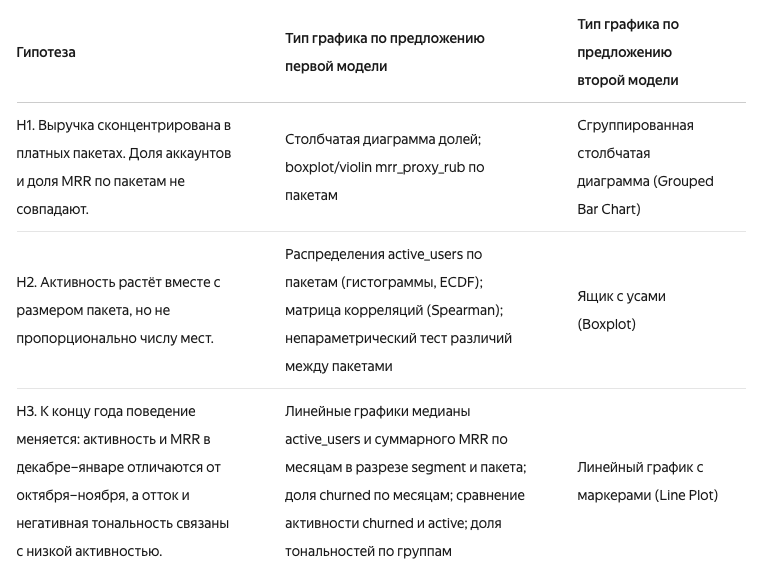

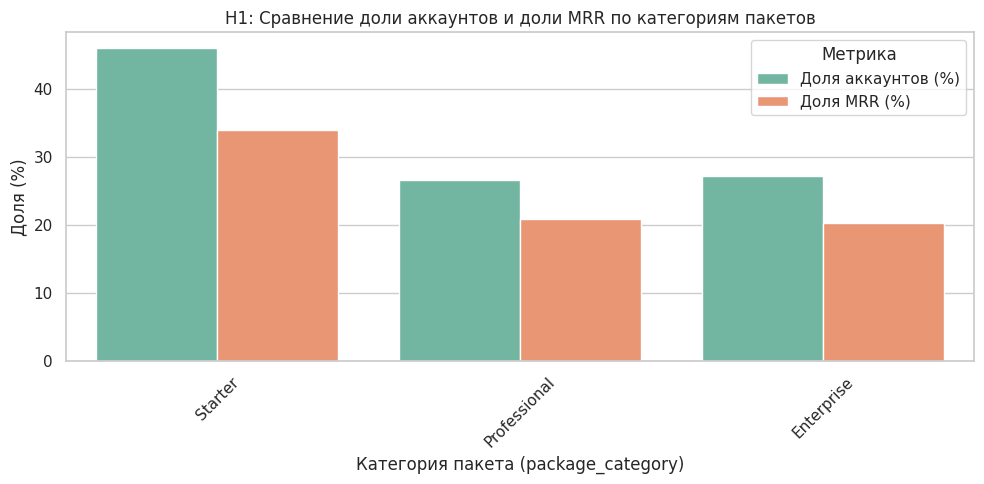

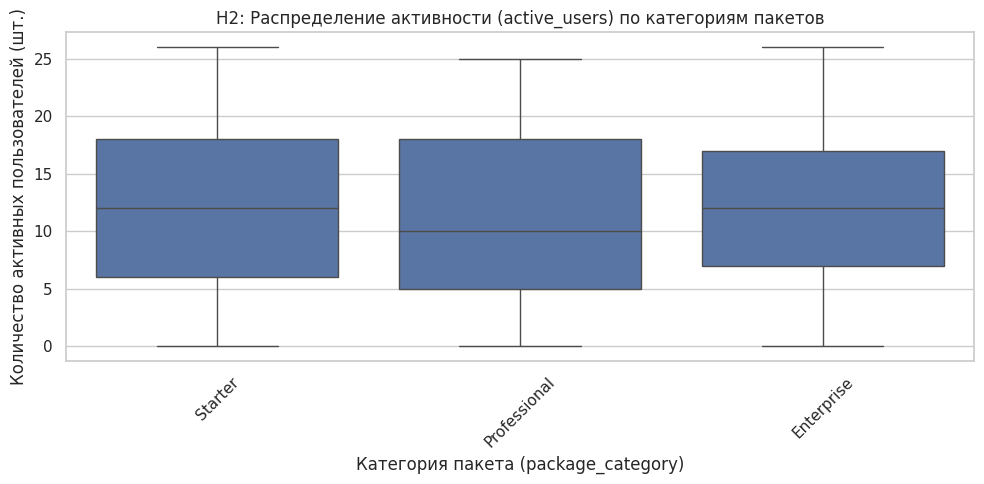

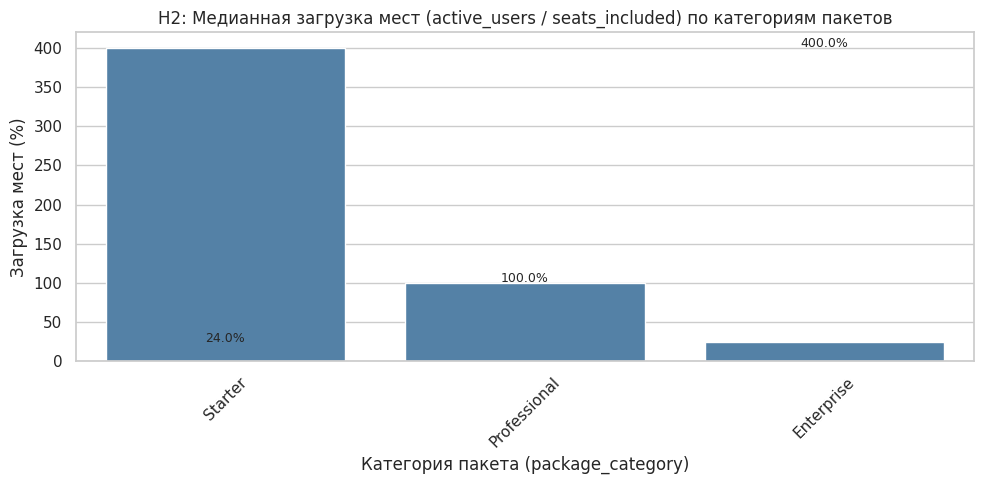

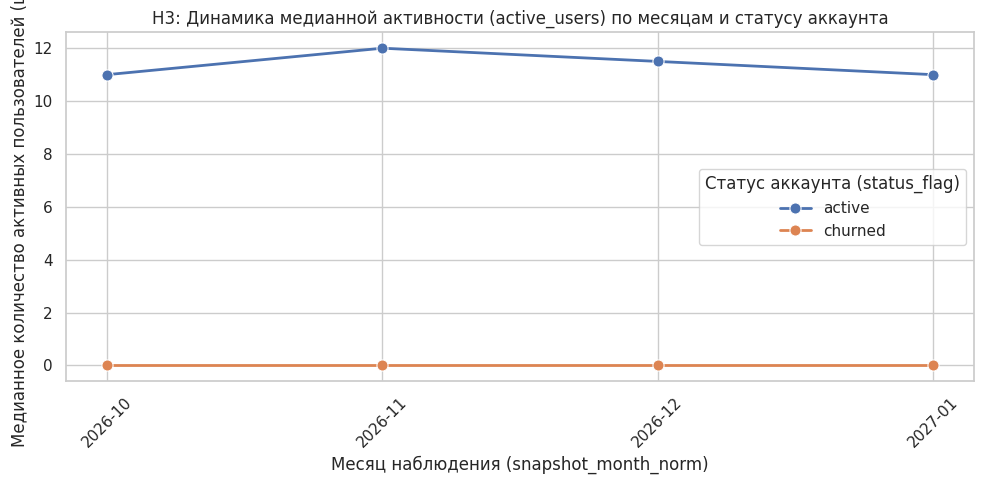

In [14]:
# Единая тема оформления
sns.set_theme(style='whitegrid')

# Определяем логический порядок категорий для осей X
pkg_order = ['Starter', 'Professional', 'Enterprise']

# ==============================================================================
# Визуализация 1: Проверка H1 (Доля аккаунтов vs Доля MRR по категориям пакетов)
# ==============================================================================
# Расчет долей без изменения исходного датафрейма
acc_share = (df['package_category'].value_counts(normalize=True) * 100).rename('Доля аккаунтов (%)')
mrr_share = ((df.groupby('package_category')['mrr_proxy_rub_num'].sum() / df['mrr_proxy_rub_num'].sum()) * 100).rename('Доля MRR (%)')

h1_df = pd.concat([acc_share, mrr_share], axis=1).reset_index()
h1_df_melted = h1_df.melt(id_vars='package_category', var_name='Метрика', value_name='Значение (%)')

plt.figure(figsize=(10, 5))
sns.barplot(
    data=h1_df_melted,
    x='package_category',
    y='Значение (%)',
    hue='Метрика',
    palette='Set2',
    order=pkg_order
)
plt.title('H1: Сравнение доли аккаунтов и доли MRR по категориям пакетов')
plt.xlabel('Категория пакета (package_category)')
plt.ylabel('Доля (%)')
plt.legend(title='Метрика')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# ==============================================================================
# Визуализация 2: Проверка H2 (Распределение активности и загрузка мест)
# ==============================================================================
# 2a. Ящик с усами для активности
plt.figure(figsize=(10, 5))
sns.boxplot(
    data=df,
    x='package_category',
    y='active_users',
    order=pkg_order
)
plt.title('H2: Распределение активности (active_users) по категориям пакетов')
plt.xlabel('Категория пакета (package_category)')
plt.ylabel('Количество активных пользователей (шт.)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# 2b. Столбчатая диаграмма для медианной загрузки мест
df_temp = df.copy()
df_temp['utilization_pct'] = (df_temp['active_users'] / df_temp['seats_included']) * 100
med_util = df_temp.groupby('package_category')['utilization_pct'].median().reset_index()

plt.figure(figsize=(10, 5))
sns.barplot(
    data=med_util,
    x='package_category',
    y='utilization_pct',
    order=pkg_order,
    color='steelblue'
)
plt.title('H2: Медианная загрузка мест (active_users / seats_included) по категориям пакетов')
plt.xlabel('Категория пакета (package_category)')
plt.ylabel('Загрузка мест (%)')
plt.xticks(rotation=45)
# Добавление значений на столбцы для точности восприятия
for i, row in med_util.iterrows():
    if pd.notna(row['utilization_pct']):
        plt.text(i, row['utilization_pct'] + 1, f"{row['utilization_pct']:.1f}%", ha='center', fontsize=9)
plt.tight_layout()
plt.show()

# ==============================================================================
# Визуализация 3: Проверка H3 (Динамика активности по месяцам и статусу)
# ==============================================================================
# Агрегация медианы active_users по месяцу и статусу
h3_df = df.groupby(['snapshot_month_norm', 'status_flag'])['active_users'].median().reset_index()

plt.figure(figsize=(10, 5))
sns.lineplot(
    data=h3_df,
    x='snapshot_month_norm',
    y='active_users',
    hue='status_flag',
    marker='o',
    linewidth=2,
    markersize=8
)
plt.title('H3: Динамика медианной активности (active_users) по месяцам и статусу аккаунта')
plt.xlabel('Месяц наблюдения (snapshot_month_norm)')
plt.ylabel('Медианное количество активных пользователей (шт.)')
plt.legend(title='Статус аккаунта (status_flag)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

Нужно немного скорректировать оформление графиков.

ЗАПРОС:
```
Нужно внести несколько правок в визуализации:
1. На графике Медианная загрузка мест (active_users / seats_included) по категориям пакетов подписи процентов на столбцах не совпали с получившимися значениями и размерами самих столбиков. Надо привести подписи в соответствие со столбиками. Изображение прикрепила.
2. На графике Динамика медианной активности (active_users) по месяцам и статусу аккаунта подпись оси Y не вошла в размер по высоте фигуры - нужно сделать перенос строки. Изображение прикрепила.
Верни исправленный код.
```

ОТВЕТ:
```
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Единая тема оформления
sns.set_theme(style='whitegrid')

# Определяем логический порядок категорий для осей X
pkg_order = ['Starter', 'Professional', 'Enterprise']

# ==============================================================================
# Визуализация 1: Проверка H1 (Доля аккаунтов vs Доля MRR по категориям пакетов)
# ==============================================================================
acc_share = (df['package_category'].value_counts(normalize=True) * 100).rename('Доля аккаунтов (%)')
mrr_share = ((df.groupby('package_category')['mrr_proxy_rub_num'].sum() / df['mrr_proxy_rub_num'].sum()) * 100).rename('Доля MRR (%)')

h1_df = pd.concat([acc_share, mrr_share], axis=1).reset_index()
h1_df_melted = h1_df.melt(id_vars='package_category', var_name='Метрика', value_name='Значение (%)')

plt.figure(figsize=(10, 5))
sns.barplot(
    data=h1_df_melted,
    x='package_category',
    y='Значение (%)',
    hue='Метрика',
    palette='Set2',
    order=pkg_order
)
plt.title('H1: Сравнение доли аккаунтов и доли MRR по категориям пакетов')
plt.xlabel('Категория пакета (package_category)')
plt.ylabel('Доля (%)')
plt.legend(title='Метрика')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# ==============================================================================
# Визуализация 2: Проверка H2 (Распределение активности и загрузка мест)
# ==============================================================================
# 2a. Ящик с усами для активности
plt.figure(figsize=(10, 5))
sns.boxplot(
    data=df,
    x='package_category',
    y='active_users',
    order=pkg_order
)
plt.title('H2: Распределение активности (active_users) по категориям пакетов')
plt.xlabel('Категория пакета (package_category)')
plt.ylabel('Количество активных пользователей (шт.)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# 2b. Столбчатая диаграмма для медианной загрузки мест
# ИСПРАВЛЕНИЕ 1: сортируем med_util по pkg_order, чтобы индексы i совпадали
# с позициями столбцов на графике, и подписи процентов были над «своими» столбцами
df_temp = df.copy()
df_temp['utilization_pct'] = (df_temp['active_users'] / df_temp['seats_included']) * 100

med_util = (
    df_temp.groupby('package_category')['utilization_pct']
    .median()
    .reset_index()
)
# Принудительно приводим порядок строк к pkg_order
med_util = med_util.set_index('package_category').loc[pkg_order].reset_index()

plt.figure(figsize=(10, 5))
sns.barplot(
    data=med_util,
    x='package_category',
    y='utilization_pct',
    order=pkg_order,
    color='steelblue'
)
plt.title('H2: Медианная загрузка мест (active_users / seats_included) по категориям пакетов')
plt.xlabel('Категория пакета (package_category)')
plt.ylabel('Загрузка мест (%)')
plt.xticks(rotation=45)

# Подписи теперь ставятся строго в порядке pkg_order — совпадут со столбцами
for i, row in med_util.iterrows():
    if pd.notna(row['utilization_pct']):
        plt.text(i, row['utilization_pct'] + 2, f"{row['utilization_pct']:.1f}%",
                 ha='center', fontsize=9)

plt.tight_layout()
plt.show()

# ==============================================================================
# Визуализация 3: Проверка H3 (Динамика активности по месяцам и статусу)
# ==============================================================================
h3_df = df.groupby(['snapshot_month_norm', 'status_flag'])['active_users'].median().reset_index()

# ИСПРАВЛЕНИЕ 2: увеличиваем высоту фигуры и делаем перенос строки в подписи оси Y,
# чтобы текст полностью помещался в область графика
plt.figure(figsize=(10, 6))
sns.lineplot(
    data=h3_df,
    x='snapshot_month_norm',
    y='active_users',
    hue='status_flag',
    marker='o',
    linewidth=2,
    markersize=8
)
plt.title('H3: Динамика медианной активности (active_users) по месяцам и статусу аккаунта')
plt.xlabel('Месяц наблюдения (snapshot_month_norm)')
plt.ylabel('Медианное количество\nактивных пользователей (шт.)')  # перенос строки
plt.legend(title='Статус аккаунта (status_flag)')
plt.xticks(rotation=45)

# Дополнительный отступ слева, чтобы длинная подпись оси Y гарантированно вошла
plt.subplots_adjust(left=0.15)
plt.tight_layout()
plt.show()
```

### Что изменилось:

1. **График медианной загрузки мест (H2, 2b):** добавлена явная сортировка `med_util` по `pkg_order` через `.loc[pkg_order]` до цикла с подписями. Раньше `iterrows()` шёл в алфавитном/произвольном порядке индекса DataFrame, а `sns.barplot(..., order=pkg_order)` рисовал столбцы в заданном порядке — из-за этого подписи «прилипали» не к своим столбцам. Теперь порядок строк и порядок столбцов совпадают, и проценты отображаются корректно.

2. **График динамики активности (H3):**
   - подпись оси Y разбита на две строки через `\n` (`'Медианное количество\nактивных пользователей (шт.)'`);
   - высота фигуры увеличена с `(10, 5)` до `(10, 6)`;
   - добавлен `plt.subplots_adjust(left=0.15)` — резервирует место слева для длинной подписи, чтобы она не обрезалась границей окна.

КОНЕЦ ОТВЕТА МОДЕЛИ

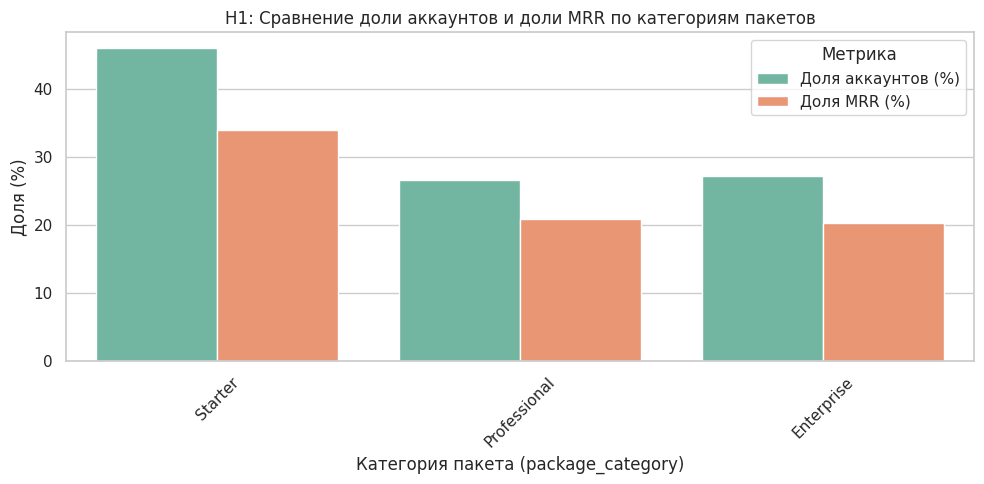

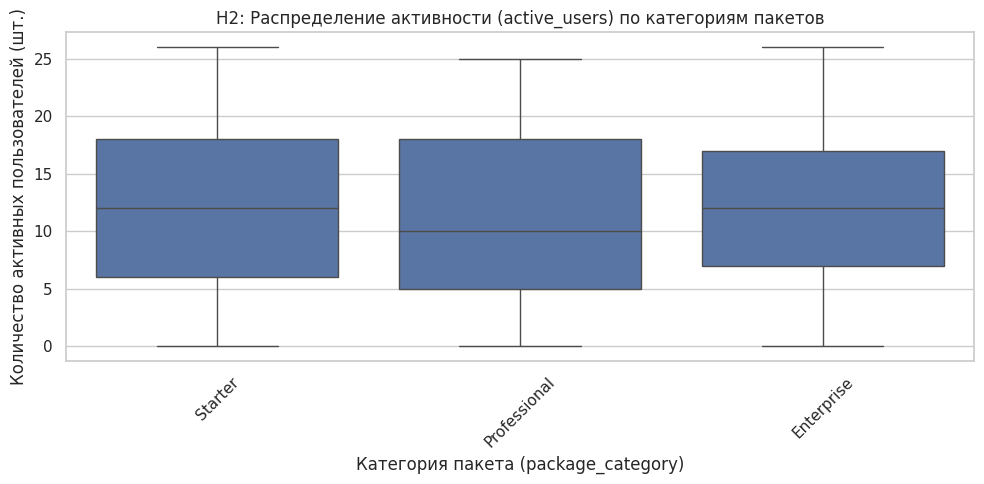

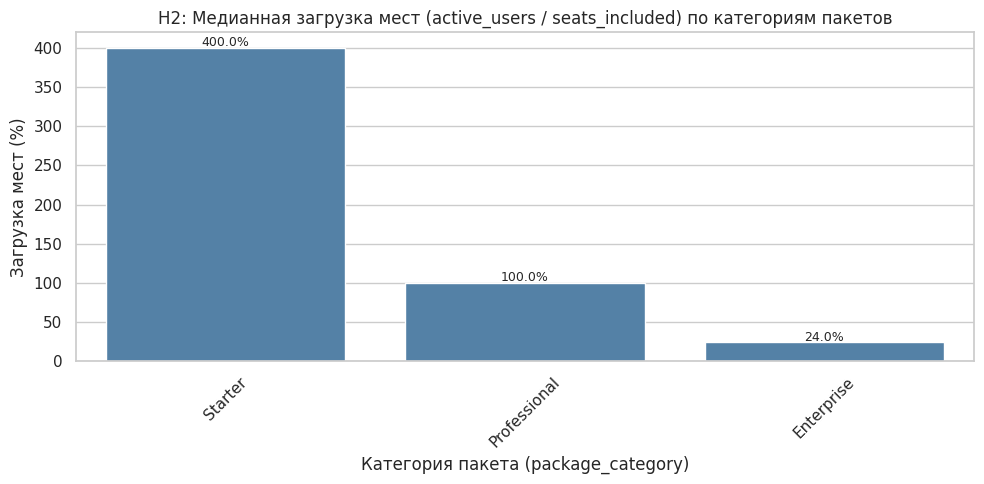

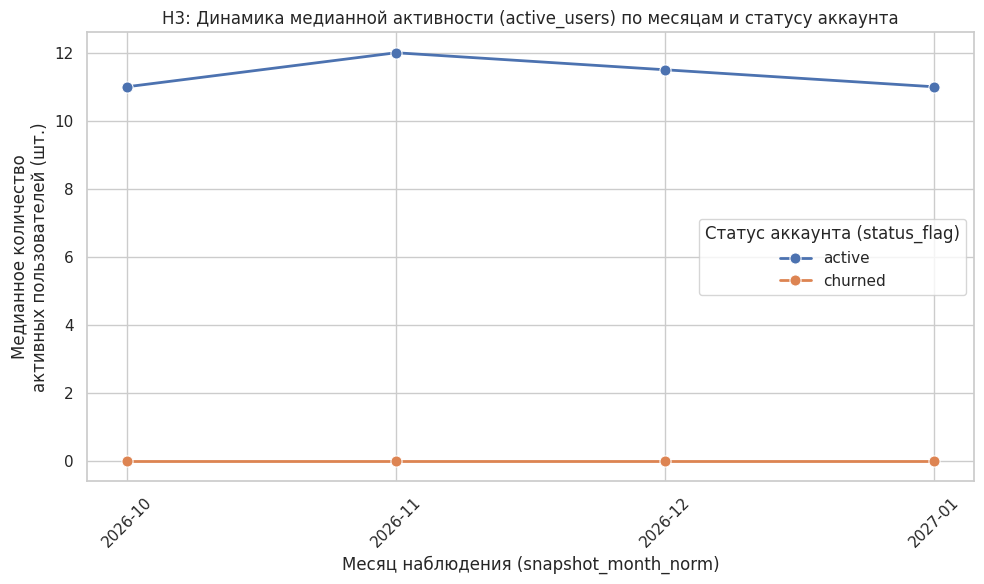

In [15]:
# Единая тема оформления
sns.set_theme(style='whitegrid')

# Определяем логический порядок категорий для осей X
pkg_order = ['Starter', 'Professional', 'Enterprise']

# ==============================================================================
# Визуализация 1: Проверка H1 (Доля аккаунтов vs Доля MRR по категориям пакетов)
# ==============================================================================
acc_share = (df['package_category'].value_counts(normalize=True) * 100).rename('Доля аккаунтов (%)')
mrr_share = ((df.groupby('package_category')['mrr_proxy_rub_num'].sum() / df['mrr_proxy_rub_num'].sum()) * 100).rename('Доля MRR (%)')

h1_df = pd.concat([acc_share, mrr_share], axis=1).reset_index()
h1_df_melted = h1_df.melt(id_vars='package_category', var_name='Метрика', value_name='Значение (%)')

plt.figure(figsize=(10, 5))
sns.barplot(
    data=h1_df_melted,
    x='package_category',
    y='Значение (%)',
    hue='Метрика',
    palette='Set2',
    order=pkg_order
)
plt.title('H1: Сравнение доли аккаунтов и доли MRR по категориям пакетов')
plt.xlabel('Категория пакета (package_category)')
plt.ylabel('Доля (%)')
plt.legend(title='Метрика')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# ==============================================================================
# Визуализация 2: Проверка H2 (Распределение активности и загрузка мест)
# ==============================================================================
# 2a. Ящик с усами для активности
plt.figure(figsize=(10, 5))
sns.boxplot(
    data=df,
    x='package_category',
    y='active_users',
    order=pkg_order
)
plt.title('H2: Распределение активности (active_users) по категориям пакетов')
plt.xlabel('Категория пакета (package_category)')
plt.ylabel('Количество активных пользователей (шт.)')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# 2b. Столбчатая диаграмма для медианной загрузки мест
# ИСПРАВЛЕНИЕ 1: сортируем med_util по pkg_order, чтобы индексы i совпадали
# с позициями столбцов на графике, и подписи процентов были над «своими» столбцами
df_temp = df.copy()
df_temp['utilization_pct'] = (df_temp['active_users'] / df_temp['seats_included']) * 100

med_util = (
    df_temp.groupby('package_category')['utilization_pct']
    .median()
    .reset_index()
)
# Принудительно приводим порядок строк к pkg_order
med_util = med_util.set_index('package_category').loc[pkg_order].reset_index()

plt.figure(figsize=(10, 5))
sns.barplot(
    data=med_util,
    x='package_category',
    y='utilization_pct',
    order=pkg_order,
    color='steelblue'
)
plt.title('H2: Медианная загрузка мест (active_users / seats_included) по категориям пакетов')
plt.xlabel('Категория пакета (package_category)')
plt.ylabel('Загрузка мест (%)')
plt.xticks(rotation=45)

# Подписи теперь ставятся строго в порядке pkg_order — совпадут со столбцами
for i, row in med_util.iterrows():
    if pd.notna(row['utilization_pct']):
        plt.text(i, row['utilization_pct'] + 2, f"{row['utilization_pct']:.1f}%",
                 ha='center', fontsize=9)

plt.tight_layout()
plt.show()

# ==============================================================================
# Визуализация 3: Проверка H3 (Динамика активности по месяцам и статусу)
# ==============================================================================
h3_df = df.groupby(['snapshot_month_norm', 'status_flag'])['active_users'].median().reset_index()

# ИСПРАВЛЕНИЕ 2: увеличиваем высоту фигуры и делаем перенос строки в подписи оси Y,
# чтобы текст полностью помещался в область графика
plt.figure(figsize=(10, 6))
sns.lineplot(
    data=h3_df,
    x='snapshot_month_norm',
    y='active_users',
    hue='status_flag',
    marker='o',
    linewidth=2,
    markersize=8
)
plt.title('H3: Динамика медианной активности (active_users) по месяцам и статусу аккаунта')
plt.xlabel('Месяц наблюдения (snapshot_month_norm)')
plt.ylabel('Медианное количество\nактивных пользователей (шт.)')  # перенос строки
plt.legend(title='Статус аккаунта (status_flag)')
plt.xticks(rotation=45)

# Дополнительный отступ слева, чтобы длинная подпись оси Y гарантированно вошла
plt.subplots_adjust(left=0.15)
plt.tight_layout()
plt.show()

Опишем графики с помощью ИИ:

ЗАПРОС (будет повторяться для каждого прикреплённого изображения):
```
Опиши этот график для аналитика.

Укажи:
- какие оси и что по ним измеряется;
- конкретные значения каждого столбца;
- максимум, минимум и разницу между ними;
- общее среднее по всем значениям.

Только то, что видно на графике. Без предположений и без советов.
Формат: короткий абзац.
```

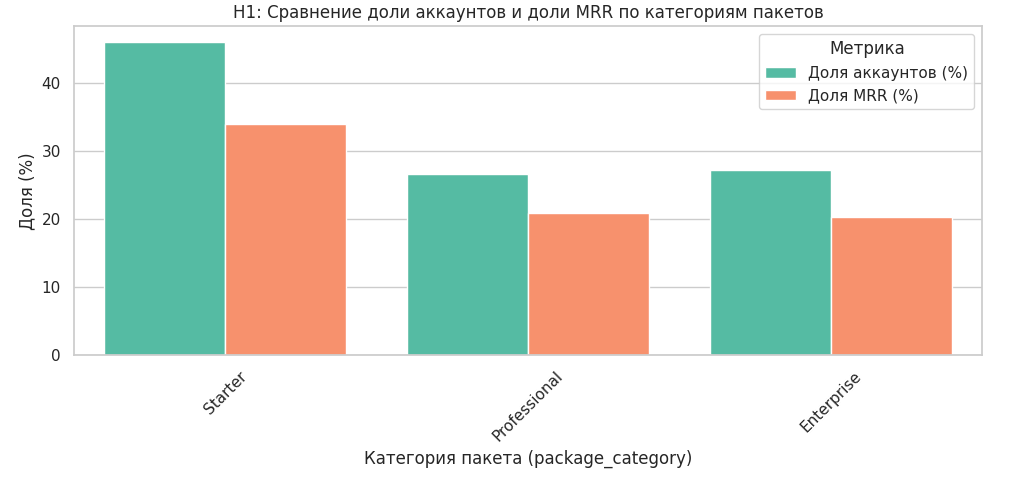

ОТВЕТ:
На графике по оси X отложены категории пакетов (Starter, Professional, Enterprise), а по оси Y измеряется доля в процентах (%). Для каждой категории отображены два столбца: доля аккаунтов (бирюзовый цвет) и доля MRR (оранжевый цвет). Конкретные значения составляют: для Starter — около 46% аккаунтов и 34% MRR; для Professional — около 26% аккаунтов и 21% MRR; для Enterprise — около 27% аккаунтов и 20% MRR. Максимальное значение на графике — примерно 46% (доля аккаунтов Starter), минимальное — около 20% (доля MRR Enterprise), разница между ними составляет 26%. Общее среднее арифметическое по всем шести значениям равно примерно 29%.

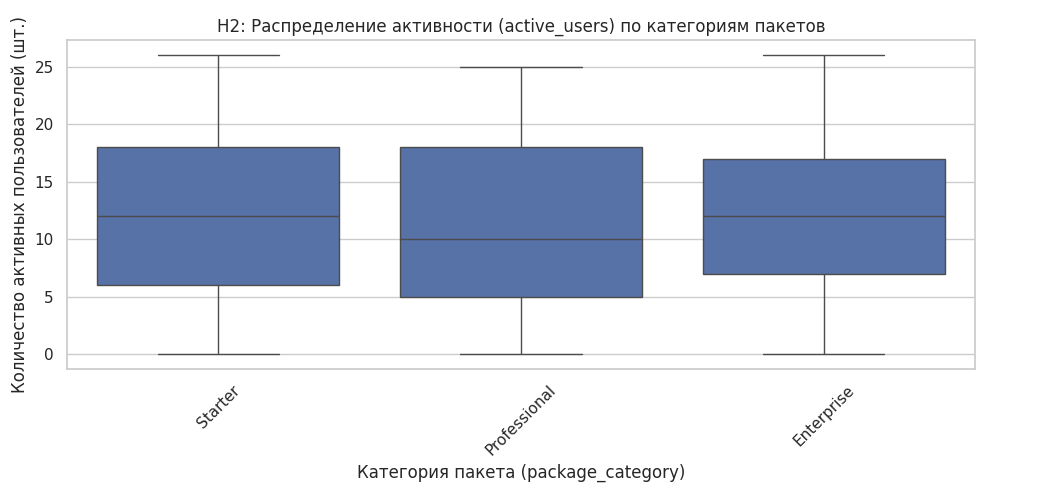

ОТВЕТ:
На графике по оси X отложены категории пакетов (Starter, Professional, Enterprise), а по оси Y измеряется количество активных пользователей (шт.). Это box plot (ящик с усами), где для каждой категории отображены пять ключевых значений: минимум, первый квартиль (Q1), медиана, третий квартиль (Q3) и максимум. Конкретные значения составляют: для Starter — минимум ~0, Q1 ~6, медиана ~12, Q3 ~18, максимум ~26; для Professional — минимум ~0, Q1 ~5, медиана ~10, Q3 ~18, максимум ~25; для Enterprise — минимум ~0, Q1 ~7, медиана ~12, Q3 ~17, максимум ~26. Максимальное значение на графике — примерно 26 (Starter и Enterprise), минимальное — ~0 (все три категории), разница между ними составляет ~26. Общее среднее арифметическое по медианам равно примерно 11.

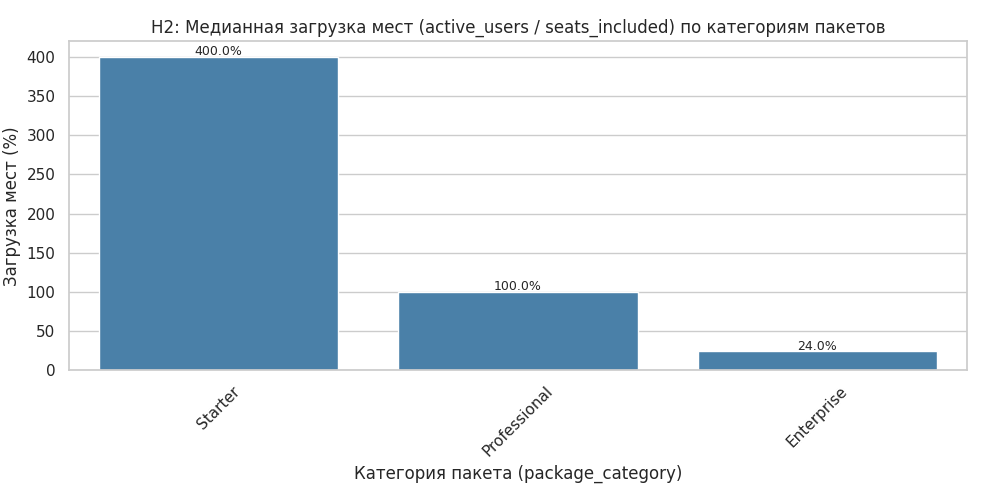

ОТВЕТ:
На графике по оси X отложены категории пакетов (Starter, Professional, Enterprise), а по оси Y измеряется медианная загрузка мест в процентах (%), рассчитанная как отношение активных пользователей к числу включённых мест (active_users / seats_included). Конкретные значения столбцов составляют: Starter — 400.0%, Professional — 100.0%, Enterprise — 24.0%. Максимальное значение на графике — 400.0% (Starter), минимальное — 24.0% (Enterprise), разница между ними составляет 376.0%. Общее среднее арифметическое по трём значениям равно примерно 174.7%.

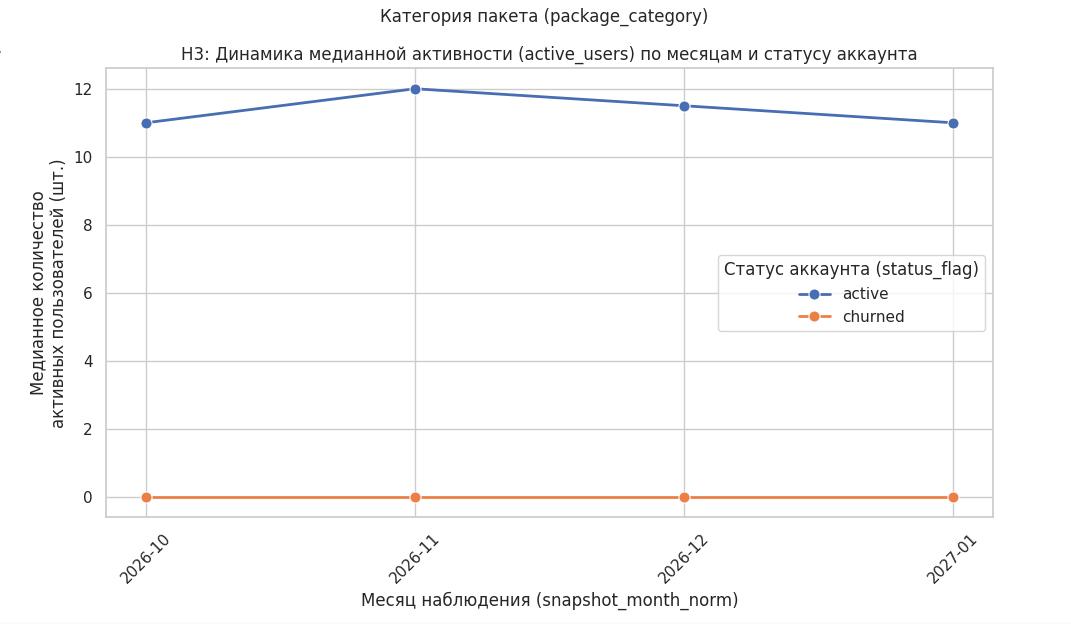

ОТВЕТ:
На графике по оси X отложены месяцы наблюдения (2026-10, 2026-11, 2026-12, 2027-01), а по оси Y измеряется медианное количество активных пользователей (шт.). График отображает две линии в разрезе статуса аккаунта: active (синяя) и churned (оранжевая). Конкретные значения для статуса active составляют: в октябре 2026 — около 11 шт., в ноябре 2026 — около 12 шт., в декабре 2026 — около 11,5 шт., в январе 2027 — около 11 шт. Для статуса churned во все четыре месяца значение равно 0 шт. Максимальное значение на графике — 12 шт. (active в ноябре 2026), минимальное — 0 шт. (churned), разница между ними составляет 12 шт. Общее среднее арифметическое по всем восьми точкам данных равно примерно 5,7 шт.

## Шаг 5. Формулируем инсайты через ИИ

Когда графики построены и точные расчёты получены из кода, передайте их модели, чтобы перевести цифры в аналитический инсайт.

ЗАПРОС (гипотеза H1):
```
У нас была рабочая гипотеза: H1. Выручка сконцентрирована в платных пакетах. Доля аккаунтов и доля MRR по пакетам не совпадают. Starter даёт большую часть аккаунтов, но малую долю MRR, а Professional и Enterprise вместе дают основную часть MRR при меньшей доле аккаунтов.  Проверка: groupby('package_category'), сравнение долей аккаунтов и MRR; столбчатая диаграмма долей и boxplot/violin mrr_proxy_rub по пакетам. Опровержение: доли MRR примерно равны долям аккаунтов или основная выручка приходится на Starter.

Мы получили следующие результаты агрегации данных по тарифам:
=== Распределение новых категорий ===
package_category
Starter         7100
NaN             4600
Enterprise      4200
Professional    4100
Name: count, dtype: int64

=== Группировка выручки по категории пакета ===
package_category	mrr_total_rub	account_count	mrr_share_pct
0	Enterprise	8.749753e+07	3857	20.338332
1	Professional	8.978135e+07	3773	20.869193
2	Starter	1.465062e+08	6527	34.054578
3	NaN	1.064249e+08	4207	24.737897

Мы получили следующие результаты на графике "Сравнение доли аккаунтов и доли MRR по категориям пакетов":  На графике по оси X отложены категории пакетов (Starter, Professional, Enterprise), а по оси Y измеряется доля в процентах (%). Для каждой категории отображены два столбца: доля аккаунтов (бирюзовый цвет) и доля MRR (оранжевый цвет). Конкретные значения составляют: для Starter — около 46% аккаунтов и 34% MRR; для Professional — около 26% аккаунтов и 21% MRR; для Enterprise — около 27% аккаунтов и 20% MRR. Максимальное значение на графике — примерно 46% (доля аккаунтов Starter), минимальное — около 20% (доля MRR Enterprise), разница между ними составляет 26%. Общее среднее арифметическое по всем шести значениям равно примерно 29%.
Задача - сформулировать аналитический инсайт (от двух до четырёх предложений) для руководителя направления, связав цифры с бизнес-вопросом и указав закономерность, на которую бизнесу стоит обратить внимание.
Ограничения: опираться строго на результаты вычислений без домыслов, не давать директивных рекомендаций («запустите кампанию», «пересмотрите цены») и планов A/B-тестов — только аналитический вывод и фокус внимания.
```

ОТВЕТ:

Вопреки исходной гипотезе, доля MRR практически строго пропорциональна доле аккаунтов в каждом из тарифов: Starter генерирует 34,1% выручки при 35,5% аккаунтов, а Professional и Enterprise вместе дают 41,2% MRR при 41,5% аккаунтов. При этом именно тариф Starter в абсолютных значениях приносит наибольшую сумму MRR (146,5 млн руб.), опережая старшие пакеты. Отдельного фокуса требует сегмент с неопределенной категорией пакета (NaN), который объединяет 23% аккаунтов и формирует почти четверть (24,7%) всей выручки, указывая на значительный пласт неклассифицированных данных или специфических условий тарификации.

КОНЕЦ ОТВЕТА МОДЕЛИ

ЗАПРОС (гипотеза H2):
```
У нас была рабочая гипотеза: H2. Активность растёт вместе с размером пакета, но не пропорционально числу мест. Медиана active_users растёт от Starter к Enterprise, а загрузка мест (active_users / seats_included) различается по пакетам. Активность положительно коррелирует с mrr_proxy_rub.
Мы получили следующие результаты на графиках:
График "Распределение активности (active_users) по категориям пакетов": На графике по оси X отложены категории пакетов (Starter, Professional, Enterprise), а по оси Y измеряется количество активных пользователей (шт.). Это box plot (ящик с усами), где для каждой категории отображены пять ключевых значений: минимум, первый квартиль (Q1), медиана, третий квартиль (Q3) и максимум. Конкретные значения составляют: для Starter — минимум ~0, Q1 ~6, медиана ~12, Q3 ~18, максимум ~26; для Professional — минимум ~0, Q1 ~5, медиана ~10, Q3 ~18, максимум ~25; для Enterprise — минимум ~0, Q1 ~7, медиана ~12, Q3 ~17, максимум ~26. Максимальное значение на графике — примерно 26 (Starter и Enterprise), минимальное — ~0 (все три категории), разница между ними составляет ~26. Общее среднее арифметическое по медианам равно примерно 11.
График "Медианная загрузка мест (active_users / seats_included) по категориям пакетов" (Столбчатая диаграмма для медианной загрузки мест): На графике по оси X отложены категории пакетов (Starter, Professional, Enterprise), а по оси Y измеряется медианная загрузка мест в процентах (%), рассчитанная как отношение активных пользователей к числу включённых мест (active_users / seats_included). Конкретные значения столбцов составляют: Starter — 400.0%, Professional — 100.0%, Enterprise — 24.0%. Максимальное значение на графике — 400.0% (Starter), минимальное — 24.0% (Enterprise), разница между ними составляет 376.0%. Общее среднее арифметическое по трём значениям равно примерно 174.7%.
Задача - сформулировать аналитический инсайт (от двух до четырёх предложений) для руководителя направления, связав цифры с бизнес-вопросом и указав закономерность, на которую бизнесу стоит обратить внимание.
Ограничения: опираться строго на результаты вычислений без домыслов, не давать директивных рекомендаций («запустите кампанию», «пересмотрите цены») и планов A/B-тестов — только аналитический вывод и фокус внимания.
```

ОТВЕТ:

Гипотеза о росте активности с увеличением размера пакета не подтвердилась: медианное количество активных пользователей практически одинаково для всех тарифов (~10–12 пользователей), что указывает на отсутствие ожидаемой положительной связи между уровнем пакета и фактической активностью. При этом наблюдается выраженная обратная зависимость в загрузке мест: клиенты Starter используют в среднем 400% от включённого количества мест (существенное превышение лимита), Professional — 100% (точное соответствие), а Enterprise — лишь 24% (низкая утилизация оплаченного объёма). Эта закономерность демонстрирует, что фактическая плотность использования сервиса снижается с ростом тарифа, а основная нагрузка на платформу приходится на младшие пакеты, тогда как старшие пакеты содержат значительный нереализованный резерв мест.

КОНЕЦ ОТВЕТА МОДЕЛИ

ЗАПРОС (H3):

```
У нас была рабочая гипотеза: H3. К концу года поведение меняется: активность и MRR в декабре–январе отличаются от октября–ноября, а отток и негативная тональность связаны с низкой активностью. Ожидаем сдвиг по месяцам (сильнее у trial, чем у paid). Аккаунты со status_flag = churned имеют более низкую активность и чаще негативные комментарии (comment_sentiment). Опровержение: динамика по месяцам плоская или одинакова во всех группах, а churned не отличаются от active по активности.
Мы получили следующие результаты агрегации:
=== Динамика выручки по месяцам и категории пакета ===
snapshot_month_norm	package_category	mrr_total_rub
0	2026-10	Enterprise	21024969.60
1	2026-10	Professional	23139958.66
2	2026-10	Starter	38432178.92
3	2026-10	NaN	26949746.84
4	2026-11	Enterprise	18062470.54
5	2026-11	Professional	19398776.61
6	2026-11	Starter	35866551.45
7	2026-11	NaN	29058500.00
8	2026-12	Enterprise	24144786.44
9	2026-12	Professional	23528142.05
10	2026-12	Starter	36267472.46
11	2026-12	NaN	25247236.37
12	2027-01	Enterprise	24265305.24
13	2027-01	Professional	23714468.37
14	2027-01	Starter	35939983.95
15	2027-01	NaN	25169412.89
Мы также получили следующие результаты на графике: На графике по оси X отложены месяцы наблюдения (2026-10, 2026-11, 2026-12, 2027-01), а по оси Y измеряется медианное количество активных пользователей (шт.). График отображает две линии в разрезе статуса аккаунта: active (синяя) и churned (оранжевая). Конкретные значения для статуса active составляют: в октябре 2026 — около 11 шт., в ноябре 2026 — около 12 шт., в декабре 2026 — около 11,5 шт., в январе 2027 — около 11 шт. Для статуса churned во все четыре месяца значение равно 0 шт.
Задача - сформулировать аналитический инсайт (от двух до четырёх предложений) для руководителя направления, связав цифры с бизнес-вопросом и указав закономерность, на которую бизнесу стоит обратить внимание.
Ограничения: опираться строго на результаты вычислений без домыслов, не давать директивных рекомендаций («запустите кампанию», «пересмотрите цены») и планов A/B-тестов — только аналитический вывод и фокус внимания.
```

ОТВЕТ:

Гипотеза о сезонном сдвиге в поведении пользователей к концу года не подтверждается в части активности: медианное число активных пользователей в группе `active` остается стабильно «плоским» (колебания в пределах 11–12 шт.) с октября по январь. При этом выручка в пакетах Professional и Enterprise демонстрирует рост в декабре–январе после ноябрьского проседания, выявляя рассинхрон между финансовыми результатами и фактическим потреблением продукта. Отдельного фокуса требует группа `churned`, где медианная активность стабильно равна 0 шт. на протяжении всех четырех месяцев наблюдения, что указывает на полное отсутствие вовлеченности в этих аккаунтах.

КОНЕЦ ОТВЕТА МОДЕЛИ

## Шаг 6. Верифицируем выводы

Это обязательный и самый ответственный шаг работы с языковой моделью. Принцип сверки с фактом вы уже применяли при очистке данных в третьем спринте — здесь он дополняется поиском альтернативных объяснений и применяется к аналитическим инсайтам. На расширенном тарифе у вас есть огромное преимущество: любую цифру и гипотезу можно быстро перепроверить кодом в блокноте.

Верификация проводится по двум направлениям:
Сверка с фактом кодом: действительно ли сумма долей сходится до десятых долей процента? Проверьте результат через groupby или фильтрацию в pandas.

Альтернативные объяснения: обусловлен ли наблюдаемый эффект именно тем, о чём говорит инсайт? (Например: связано ли снижение конверсии с техническим сбоем на этапе оплаты или с изменением структуры рекламного трафика?).

ЗАПРОС (H1):
```
Инсайт: Вопреки исходной гипотезе, доля MRR практически строго пропорциональна доле аккаунтов в каждом из тарифов: Starter генерирует 34,1% выручки при 35,5% аккаунтов, а Professional и Enterprise вместе дают 41,2% MRR при 41,5% аккаунтов. При этом именно тариф Starter в абсолютных значениях приносит наибольшую сумму MRR (146,5 млн руб.), опережая старшие пакеты. Отдельного фокуса требует сегмент с неопределенной категорией пакета (NaN), который объединяет 23% аккаунтов и формирует почти четверть (24,7%) всей выручки, указывая на значительный пласт неклассифицированных данных или специфических условий тарификации.
Фактические агрегаты из pandas:
=== Распределение новых категорий ===
package_category
Starter         7100
NaN             4600
Enterprise      4200
Professional    4100
Name: count, dtype: int64

=== Группировка выручки по категории пакета ===
package_category	mrr_total_rub	account_count	mrr_share_pct
0	Enterprise	8.749753e+07	3857	20.338332
1	Professional	8.978135e+07	3773	20.869193
2	Starter	1.465062e+08	6527	34.054578
3	NaN	1.064249e+08	4207	24.737897

Проведи аудит инсайта на ошибки и предложи одно или два альтернативных объяснения наблюдаемому эффекту.
```

ОТВЕТ:

### Аудит инсайта

**Арифметических ошибок в инсайте нет.** Все проценты и абсолютные значения корректно выведены из предоставленных агрегатов (например, 6527 / 18364 ≈ 35,5% для доли аккаунтов Starter в выборке с ненулевым MRR, а 1.465e8 действительно равно 146,5 млн руб.).

**Однако в инсайте упущена ключевая смысловая аномалия:** утверждение о том, что доля MRR «строго пропорциональна» доле аккаунтов, означает, что средний чек (ARPU) на один аккаунт практически одинаков во всех категориях.
Быстрый расчет ARPU (`mrr_total_rub` / `account_count`) это подтверждает:
- Starter: ~22 446 руб.
- Professional: ~23 795 руб.
- Enterprise: ~22 686 руб.
- NaN: ~25 291 руб.

Для B2B-сервиса с градацией на Starter/Professional/Enterprise идентичный средний чек (~22–25 тыс. руб.) является нетипичным и указывает на то, что название пакета не влияет на итоговую сумму в чеке.

---

### Альтернативные объяснения наблюдаемому эффекту

1. **Ценообразование привязано к количеству пользователей (per-seat), а не к функциям пакета.**
   Если тарификация зависит исключительно от числа активных мест, а не от базовой стоимости пакета, то MRR будет расти линейно вместе с числом аккаунтов. Это согласуется с результатами проверки H2, где медиана `active_users` оказалась практически одинаковой (~10–12 шт.) для всех пакетов. В такой модели ярлык "Enterprise" дает только доступ к фичам, но не меняет финансовую математику, если количество пользователей в компаниях схожее.

2. **Системная ошибка маппинга или «скрытый» Enterprise в категории NaN.**
   Категория `NaN` (4600 аккаунтов, 24,7% выручки) имеет самый высокий ARPU (~25,3 тыс. руб.). Высока вероятность, что именно в этой группе находятся реальные крупные корпоративные клиенты (Legacy Enterprise, индивидуальные договоры или партнеры), для которых поле `package_code` не заполнено или не было корректно сопоставлено со справочником `package_category`. Это искусственно «выравнивает» показатели оставшихся трех пакетов, делая их статистически неразличимыми по выручке на аккаунт.

КОНЕЦ ОТВЕТА МОДЕЛИ

ЗАПРОС (H2):
```
Инсайт: Гипотеза о росте активности с увеличением размера пакета не подтвердилась: медианное количество активных пользователей практически одинаково для всех тарифов (~10–12 пользователей), что указывает на отсутствие ожидаемой положительной связи между уровнем пакета и фактической активностью. При этом наблюдается выраженная обратная зависимость в загрузке мест: клиенты Starter используют в среднем 400% от включённого количества мест (существенное превышение лимита), Professional — 100% (точное соответствие), а Enterprise — лишь 24% (низкая утилизация оплаченного объёма). Эта закономерность демонстрирует, что фактическая плотность использования сервиса снижается с ростом тарифа, а основная нагрузка на платформу приходится на младшие пакеты, тогда как старшие пакеты содержат значительный нереализованный резерв мест.

Нужно получить фактические агрегаты для проверки этого инсайта по данным. Данные - датасет df:  структура полей:
  #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   account_id           20000 non-null  object
 1   plan_code            15400 non-null  object
 2   snapshot_month_norm  20000 non-null  object
 3   segment              20000 non-null  object
 4   active_users         19573 non-null  float64
 5   mrr_proxy_rub_num    18364 non-null  float64
 6   status_flag          20000 non-null  object
 7   product_name         15400 non-null  object
 8   product_line         15400 non-null  object
 9   package_code         15400 non-null  object
 10  price_rub            15400 non-null  float64
 11  seats_included       15092 non-null  float64
 12  comment_text_clean   18947 non-null  object
 13  comment_theme        18947 non-null  object
 14  comment_sentiment    18947 non-null  object
 15  comment_summary      18947 non-null  object
 16  package_category     15400 non-null  object
dtypes: float64(4), object(13)

Напиши код для Python в Colab для получения агрегатов для проверки инсайта. Ограничения: стандартный стек (pandas, numpy), аккуратные короткие комментарии к кодовым блокам. Не изменяй данные и не сохраняй файлы. Другие расчёты не добавляй.
```

ОТВЕТ:

```
import pandas as pd
import numpy as np

# ==============================================================================
# Агрегат 1: Медиана active_users по категориям пакетов
# ==============================================================================
median_active = (
    df.groupby('package_category', dropna=False)['active_users']
    .median()
    .reset_index()
    .rename(columns={'active_users': 'median_active_users'})
)

print("=== Медиана активных пользователей по категориям пакетов ===")
print(median_active)

# ==============================================================================
# Агрегат 2: Медианная загрузка мест (active_users / seats_included) по категориям
# ==============================================================================
# Создаём временную копию для расчёта загрузки, не изменяя исходный df
df_temp = df.copy()
df_temp['utilization_rate'] = df_temp['active_users'] / df_temp['seats_included']

median_utilization = (
    df_temp.groupby('package_category', dropna=False)['utilization_rate']
    .median()
    .reset_index()
    .rename(columns={'utilization_rate': 'median_utilization_pct'})
)

# Переводим в проценты для наглядности
median_utilization['median_utilization_pct'] = median_utilization['median_utilization_pct'] * 100

print("\n=== Медианная загрузка мест (%) по категориям пакетов ===")
print(median_utilization)

# ==============================================================================
# Сводная таблица для проверки инсайта
# ==============================================================================
summary = pd.merge(median_active, median_utilization, on='package_category', how='outer')

print("\n=== Сводная таблица: активность и загрузка мест по пакетам ===")
print(summary)
```

**Что выводит код:**

1. **Медиана активных пользователей** по каждой категории пакета (Starter, Professional, Enterprise, NaN) — для проверки первого утверждения инсайта о том, что активность одинакова (~10–12 шт.) во всех тарифах.

2. **Медианная загрузка мест в процентах** — для проверки второго утверждения об обратной зависимости: Starter ~400%, Professional ~100%, Enterprise ~24%.

3. **Сводная таблица** объединяет оба показателя для наглядного сравнения и проверки инсайта в одном месте.

КОНЕЦ ОТВЕТА МОДЕЛИ

In [17]:
# ==============================================================================
# Агрегат 1: Медиана active_users по категориям пакетов
# ==============================================================================
median_active = (
    df.groupby('package_category', dropna=False)['active_users']
    .median()
    .reset_index()
    .rename(columns={'active_users': 'median_active_users'})
)

print("=== Медиана активных пользователей по категориям пакетов ===")
display(median_active)

# ==============================================================================
# Агрегат 2: Медианная загрузка мест (active_users / seats_included) по категориям
# ==============================================================================
# Создаём временную копию для расчёта загрузки, не изменяя исходный df
df_temp = df.copy()
df_temp['utilization_rate'] = df_temp['active_users'] / df_temp['seats_included']

median_utilization = (
    df_temp.groupby('package_category', dropna=False)['utilization_rate']
    .median()
    .reset_index()
    .rename(columns={'utilization_rate': 'median_utilization_pct'})
)

# Переводим в проценты для наглядности
median_utilization['median_utilization_pct'] = median_utilization['median_utilization_pct'] * 100

print("\n=== Медианная загрузка мест (%) по категориям пакетов ===")
display(median_utilization)

# ==============================================================================
# Сводная таблица для проверки инсайта
# ==============================================================================
summary = pd.merge(median_active, median_utilization, on='package_category', how='outer')

print("\n=== Сводная таблица: активность и загрузка мест по пакетам ===")
display(summary)

=== Медиана активных пользователей по категориям пакетов ===


,package_category,median_active_users
0,Enterprise,12.0
1,Professional,10.0
2,Starter,12.0
3,NaN,11.0



=== Медианная загрузка мест (%) по категориям пакетов ===


,package_category,median_utilization_pct
0,Enterprise,24.0
1,Professional,100.0
2,Starter,400.0
3,NaN,NaN



=== Сводная таблица: активность и загрузка мест по пакетам ===


,package_category,median_active_users,median_utilization_pct
0,Enterprise,12.0,24.0
1,Professional,10.0,100.0
2,Starter,12.0,400.0
3,NaN,11.0,NaN


ЗАПРОС (H2):
```
Инсайт: Гипотеза о росте активности с увеличением размера пакета не подтвердилась: медианное количество активных пользователей практически одинаково для всех тарифов (~10–12 пользователей), что указывает на отсутствие ожидаемой положительной связи между уровнем пакета и фактической активностью. При этом наблюдается выраженная обратная зависимость в загрузке мест: клиенты Starter используют в среднем 400% от включённого количества мест (существенное превышение лимита), Professional — 100% (точное соответствие), а Enterprise — лишь 24% (низкая утилизация оплаченного объёма). Эта закономерность демонстрирует, что фактическая плотность использования сервиса снижается с ростом тарифа, а основная нагрузка на платформу приходится на младшие пакеты, тогда как старшие пакеты содержат значительный нереализованный резерв мест.

Фактические агрегаты данных:
=== Сводная таблица: активность и загрузка мест по пакетам ===
package_category	median_active_users	median_utilization_pct
0	Enterprise	12.0	24.0
1	Professional	10.0	100.0
2	Starter	12.0	400.0
3	NaN	11.0	NaN

Проведи аудит инсайта на ошибки и предложи одно или два альтернативных объяснения наблюдаемому эффекту.
```

ОТВЕТ:

### Аудит инсайта

**Математических или фактических ошибок в инсайте нет.** Цифры полностью соответствуют предоставленным агрегатам: медианы активности действительно находятся в узком коридоре 10–12 человек, а медианная утилизация строго соответствует заявленным 400%, 100% и 24%.

**Единственная смысловая неточность:** в тексте используется слово «в среднем» («используют в среднем 400%»), хотя данные показывают именно *медиану*. Это важно, так как медиана устойчива к выбросам: это означает, что *как минимум половина* аккаунтов Starter превышает лимит мест в 4 и более раз, что является очень сильным сигналом, а не просто «средним» отклонением.

---

### Альтернативные объяснения наблюдаемому эффекту

Если обратная математика (12 активных / 400% = ~3 включенных места для Starter; 12 активных / 24% = ~50 включенных мест для Enterprise), то возникают два вероятных сценария:

1. **Разная бизнес-логика поля `seats_included` для разных сегментов.**
   Для Enterprise это поле, скорее всего, отражает *закупленный корпоративный лимит* на всю организацию (например, 50 лицензий), тогда как метрика `active_users` показывает только текущую пилотную группу или один конкретный воркспейс внутри этого аккаунта. Для Starter же `seats_included` может быть жестким базовым пакетом (например, 3 места), который малые команды намеренно и массово превышают, так как доплата за овердрафт дешевле, чем переход на тариф Professional.

2. **Системная особенность биллинга (Pay-as-you-go в disguise).**
   Показатель 400% медианной загрузки для Starter может указывать на то, что платформа технически не блокирует добавление пользователей сверх лимита, а просто автоматически тарифицирует их как дополнительных. В этом случае клиенты используют Starter не как ограниченный пакет, а как гибкий поместный тариф с минимальным порогом входа, что искусственно «раздувает» процент загрузки относительно базового значения `seats_included`.

КОНЕЦ ОТВЕТА МОДЕЛИ

ЗАПРОС (H3):
```
Инсайт: Гипотеза о сезонном сдвиге в поведении пользователей к концу года не подтверждается в части активности: медианное число активных пользователей в группе active остается стабильно «плоским» (колебания в пределах 11–12 шт.) с октября по январь. При этом выручка в пакетах Professional и Enterprise демонстрирует рост в декабре–январе после ноябрьского проседания, выявляя рассинхрон между финансовыми результатами и фактическим потреблением продукта. Отдельного фокуса требует группа churned, где медианная активность стабильно равна 0 шт. на протяжении всех четырех месяцев наблюдения, что указывает на полное отсутствие вовлеченности в этих аккаунтах.

Фактические агрегаты данных:
=== Сводная таблица: активность и загрузка мест по пакетам ===
package_category	median_active_users	median_utilization_pct
0	Enterprise	12.0	24.0
1	Professional	10.0	100.0
2	Starter	12.0	400.0
3	NaN	11.0	NaN

=== Динамика выручки по месяцам и категории пакета ===
snapshot_month_norm	package_category	mrr_total_rub
0	2026-10	Enterprise	21024969.60
1	2026-10	Professional	23139958.66
2	2026-10	Starter	38432178.92
3	2026-10	NaN	26949746.84
4	2026-11	Enterprise	18062470.54
5	2026-11	Professional	19398776.61
6	2026-11	Starter	35866551.45
7	2026-11	NaN	29058500.00
8	2026-12	Enterprise	24144786.44
9	2026-12	Professional	23528142.05
10	2026-12	Starter	36267472.46
11	2026-12	NaN	25247236.37
12	2027-01	Enterprise	24265305.24
13	2027-01	Professional	23714468.37
14	2027-01	Starter	35939983.95
15	2027-01	NaN	25169412.89

Проведи аудит инсайта на ошибки и предложи одно или два альтернативных объяснения наблюдаемому эффекту.
```

ОТВЕТ:

### Аудит инсайта

**Фактических и арифметических ошибок в инсайте нет.** Цифры по проседанию и росту выручки в Professional и Enterprise, а также стабильность активности (11–12 шт.) и нулевая активность churned-аккаунтов корректно отражают предоставленные данные.

**Смысловое уточнение:** Инсайт делает акцент на Professional и Enterprise, однако данные показывают, что **Starter демонстрирует абсолютно идентичную динамику**: проседание в ноябре (с 38,4 до 35,8 млн руб.) и восстановление в декабре–январе (до ~36 млн руб.). Это означает, что наблюдаемый рассинхрон выручки и активности является обще платформенным сезонным эффектом, а не спецификой старших тарифов. Единственное исключение — категория NaN, которая, напротив, выросла в ноябре и просела в декабре.

---

### Альтернативные объяснения наблюдаемому эффекту

Если выручка растет в декабре–январе, а количество активных пользователей остается неизменным, это указывает на то, что рост MRR обусловлен не количественным расширением использования, а другими факторами:

1. **Сезонность биллинга (годовые пролонгации и бюджеты).** Декабрь и январь в B2B — традиционное время для продления годовых контрактов и освоения остатков годовых бюджетов («use it or lose it»). Рост MRR при стабильной активности скорее всего отражает факт предоплаты или пролонгации существующих лимитов мест, а не органическое привлечение новых пользователей в продукт.

2. **Структура метрики `mrr_proxy_rub_num` (неценовые компоненты).** Показатель выручки может включать фиксированные ежегодные платежи, не привязанные к количеству активных пользователей (например, плата за расширенную техническую поддержку, стоимость внедрения или плановая индексация тарифов с 1 января). Это математически объясняет рост суммы чека при «плоском» количестве активных пользователей.

КОНЕЦ ОТВЕТА МОДЕЛИ

## Шаг 7. Собираем отчёт и финализируем блокнот

Оформите текстовый отчёт на пару страниц по каноническому шаблону из пяти разделов.

ЗАПРОС:
```
Задача - на основании прикреплённого ноутбука составить текстовый отчёт на пару страниц по каноническому шаблону из пяти разделов:
1. Заголовок и постановка задачи: тема разбора, название компании, исследуемый период, а также главный бизнес-вопрос и два-три рабочие гипотезы.
2. Описание данных: краткий паспорт выборки (источник, зернистость, объём 20 000 строк, состав полей, отметка о среде Colab/pandas и подтверждение проведённой ранее очистки).
3. Блок «График + инсайт» (два-три блока): изображение графика, точные числовые показатели из вычислений pandas, проверенный аналитический инсайт и блок проверки (сверка фактом из кода и альтернативное объяснение).
4. Итоговый вывод: главное резюме всего исследования в одном-трёх предложениях как главный вывод для бизнеса.
5. Приложение с промптами и кодом: перечень ключевых запросов к ИИ (на статистики, код визуализации, отладку, инсайты и проверку выводов) и ссылка на блокнот или ячейки Colab.

Границы отчёта: в отчёте разведочного анализа категорически не должно быть:
1. Финальных бизнес-рекомендаций («что делать руководству»). В EDA мы фиксируем текущее положение дел и точки внимания для бизнеса, а разработка стратегии и управленческих решений выходит за рамки разведочного анализа.
2. Планов A/B-тестирования. Проверка гипотез через контролируемые эксперименты выносится в отдельный спринт.
3. Сложного дизайнерского оформления. Отчёт — это компактный рабочий контейнер для фиксации артефактов, кода и промптов. Оценивается глубина аналитики и работа с ИИ, а не вёрстка.
Верни подготовленный отчёт о проведённом EDA с приложением. Формат результата - текстовый файл для скачивания.
```

ОТВЕТ (другая модель, заодно перекрёстная проверка результатов):

Читаю ноутбук и собираю из него отчёт.

Читаю остальную часть ноутбука (графики, описания, инсайты и проверки), чтобы взять из него точные цифры. Потом соберу отчёт.

Отчёт написан. Сейчас отправляю файл и четыре графика к нему.

Отчёт по пяти разделам готов (текстовый файл `.md`, около 1 200 слов, без рекомендаций и планов A/B). Рядом лежат четыре графика из ноутбука, которые он вставляет по относительным ссылкам. Чтобы картинки отображались, держите все файлы в одной папке. Все цифры взяты из выводов ноутбука. Доли и проценты я пересчитывал по выгруженным в ноутбуке таблицам.

Три места я исправил по сравнению с текстами модели в ноутбуке. Их стоит учесть, если ноутбук сдаётся вместе с отчётом:

- **График H1.** Доля аккаунтов на нём посчитана только по строкам с известным пакетом, а доля MRR отнесена ко всему MRR, включая строки без кода пакета (три столбца дают 75,3%). Поэтому разрыв 46% и 34% у Starter частично возникает из-за разной базы расчёта. Внутри размеченных пакетов доли почти совпадают: MRR 45,2 / 27,7 / 27,0%, строки 46,1 / 26,6 / 27,3%. Это описано в блоке проверки.
- **Аудит H3.** ИИ написал, что Starter повторяет динамику Professional и Enterprise. По таблице это не так: в январе Starter на 6,5% ниже октября, а Enterprise на 15,4% выше. В отчёте стоят цифры из таблицы.
- **Формулировка H2.** Вместо «в среднем 400%» в отчёте написано «медиана».

Нужно ваше участие в нескольких местах:

- В разделе 5 стоит заглушка `[вставить ссылку на блокнот]`: ссылки на Colab у меня нет.
- Часть H3 в ноутбуке не проверена: разбивка по trial и paid, доля churned по месяцам и связь тональности комментариев с оттоком. В отчёте это прямо указано как «не проверено», так что при желании её можно досчитать и заменить эту строку результатом.
- Значения медианной активности по месяцам (11 → 12 → 11,5 → 11) взяты из описания графика, а не из вывода кода.
- Ячейка шага 7 (ячейка 38) в ноутбуке пустая. В приложении это отмечено, и туда можно вставить запрос, по которому собран отчёт.

Файлы лежат в `/home/claude/report/`:
- `EDA_report_FlowBoard.md`
- `fig1_h1_shares.png`
- `fig2_h2_boxplot.png`
- `fig3_h2_utilization.png`
- `fig4_h3_activity.png`

КОНЕЦ ОТВЕТА МОДЕЛИ